# Sample representativeness: panel users per 2 km (headline) and 1 km² census cell against census population

Same check as Supplementary Material B (section 2) of Marin-Flores, Dey, Zhang, Arcaute & Tenkanen (2026,
`07_supplementary/B_representativeness_home_work.ipynb` in `AaltoGIS/carbon_budget_nature`), applied to the German, French and British cities:

1. each panel user is placed at the centre of their **home H3 level-9 cell** (one record per user, the two-month rule of the city notebooks);
2. that point is assigned to the **1 km × 1 km cell of the European reference grid** it falls in (EPSG:3035, the EU-wide counterpart of the
   Statistics Finland 1 km grid used in the paper). Population per cell comes from the **Eurostat Census 2021 grid** (`ESTAT_Census_2021_V2`) for
   Germany and France. That file has no UK cells, so for the British cities the population of the same 1 km cells is built from the **census Output Areas**
   (ONS Census 2021 for England and Wales, NRS Census 2022 for Scotland: each OA's residents are put in the cell its centroid falls in; OAs are
   0.03–0.06 km² in cities, so the assignment loses little), the UK counterpart of the Eurostat census grid; the **JRC-GEOSTAT 2018 grid**
   (`JRC_1K_POP_2018`, residents at 30 June 2018 downscaled by the JRC to the same cells) is kept as a second source for the UK. The two grids share the cell ids;
   on the cells they have in common the 2018 and 2021 totals agree within 1% and correlate at 0.99, and for the Berlin, Paris and Munich FUAs
   the 2018 totals are within 2% of the census 2021 ones, so the UK numbers are comparable with a ~2% older-population caveat;
3. users per grid cell are plotted against census population per grid cell on log–log axes with a fitted regression line, R² and p-value,
   once for all cells with users and population, once for cells with at least 5 residents and at least 1 user;
4. penetration (users / population) per grid cell: mean and median.

The grids are used as they are; nothing is reweighted or transferred to another unit. Home cells come from the level-9 user-day tables
(`<COUNTRY>_userday_h3_9_<month>`), so the home rule is applied at the same resolution as in the paper.

In [1]:
import os, re, time, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, h3, duckdb
import matplotlib.pyplot as plt
from scipy.stats import linregress

# ---- parameters -------------------------------------------------------------
ALL_CITY_KEYS = ["berlin", "munich", "hamburg", "frankfurt", "cologne", "paris", "lyon", "marseille", "nice",            # Toulouse excluded (decision of 2026-11-23)
                 "london", "manchester", "birmingham", "glasgow", "liverpool"]
CITY_KEYS = [k for k in os.environ.get("LOCO_CITIES", ",".join(ALL_CITY_KEYS)).split(",") if k]   # LOCO_CITIES=london,glasgow runs a subset; results are merged into the saved summaries
PERIOD    = "2024-05_2024-06"
H3_RES    = 9                       # home cells at level 9, as in the paper
H_MIN, W_MIN = 10, 4                # same thresholds as the city notebooks
POP_MIN, USERS_MIN = 10, 2          # cells kept for the filtered fit and the penetration (the Finnish paper used 5 and 1)
FIGURE_DPI = 150

# same city table as the city notebooks (Urban Audit codes, public holidays per month used for the working days)
CITIES = {
    "munich":    dict(country="DEU", name="Munich",    city="DE003C", fua="DE003F", holidays={"2024-05": [1, 9, 20, 30], "2024-06": []}),
    "berlin":    dict(country="DEU", name="Berlin",    city="DE001C", fua="DE001F", holidays={"2024-05": [1, 9, 20], "2024-06": []}),
    "hamburg":   dict(country="DEU", name="Hamburg",   city="DE002C", fua="DE002F", holidays={"2024-05": [1, 9, 20], "2024-06": []}),
    "frankfurt": dict(country="DEU", name="Frankfurt", city="DE005C", fua="DE005F", holidays={"2024-05": [1, 9, 20, 30], "2024-06": []}),
    "cologne":   dict(country="DEU", name="Cologne",   city="DE004C", fua="DE004F", holidays={"2024-05": [1, 9, 20, 30], "2024-06": []}),
    "paris":     dict(country="FRA", name="Paris",     city="FR001C", fua="FR001F", holidays={"2024-05": [1, 8, 9, 20], "2024-06": []}),
    "lyon":      dict(country="FRA", name="Lyon",      city="FR002C", fua="FR002F", holidays={"2024-05": [1, 8, 9, 20], "2024-06": []}),
    "marseille": dict(country="FRA", name="Marseille", city="FR004C", fua="FR004F", holidays={"2024-05": [1, 8, 9, 20], "2024-06": []}),
    "toulouse":  dict(country="FRA", name="Toulouse",  city="FR006C", fua="FR006F", holidays={"2024-05": [1, 8, 9, 20], "2024-06": []}),
    "nice":      dict(country="FRA", name="Nice",      city="FR008C", fua="FR008F", holidays={"2024-05": [1, 8, 9, 20], "2024-06": []}),
    # United Kingdom (Urban Audit 2020 edition, the last with UK boundaries): bank holidays 6 and 27 May 2024, none in June
    "london":     dict(country="GBR", name="London",     city=[f"UK{n}C1" for n in range(101, 134)], fua="UK001L3", holidays={"2024-05": [6, 27], "2024-06": []}),
    "manchester": dict(country="GBR", name="Manchester", city="UK008C1", fua="UK008L3", holidays={"2024-05": [6, 27], "2024-06": []}),
    "birmingham": dict(country="GBR", name="Birmingham", city="UK002C1", fua="UK002L3", holidays={"2024-05": [6, 27], "2024-06": []}),
    "glasgow":    dict(country="GBR", name="Glasgow",    city="UK004C1", fua="UK004L1", holidays={"2024-05": [6, 27], "2024-06": []}),
    "liverpool":  dict(country="GBR", name="Liverpool",  city="UK006C1", fua="UK006L3", holidays={"2024-05": [6, 27], "2024-06": []}),
}
MONTHS = PERIOD.split("_")
NIGHT_HOURS = [22, 23, 0, 1, 2, 3, 4, 5, 6]; WORK_HOURS = [9, 10, 11, 12, 13, 14, 15, 16]; WORKDAYS = [1, 2, 3, 4, 5]
SCRATCH = Path(f"/scratch/project_2022768/{os.environ['USER']}/locomizer")
GRID_CRS = "EPSG:3035"
# population grids on the 1 km European reference grid: Eurostat Census 2021 for EU countries, JRC-GEOSTAT 2018 for the UK (no UK cells in the 2021 file)
GRID_FILES = {"Census 2021 (Eurostat)":  SCRATCH / "boundaries" / "census_grid_2021" / "ESTAT_Census_2021_V2.parquet",
              "JRC-GEOSTAT 2018 (JRC)": SCRATCH / "boundaries" / "jrc_grid_2018" / "JRC_1K_POP_2018.parquet"}     # parquet made from JRC_1K_POP_2018.tif: GRD_ID, N, E, T
OA_SOURCE = "Census 2021/22 OAs (ONS/NRS)"                                                                        # UK census Output Areas put on the same 1 km grid by centroid
OA_CENTROIDS = SCRATCH / "boundaries" / "uk_oa" / "uk_oa_population_centroids.parquet"                           # one row per OA: lon, lat, population (built 2026-11-23)
POP_SOURCES = {"DEU": ["Census 2021 (Eurostat)"], "FRA": ["Census 2021 (Eurostat)"], "GBR": [OA_SOURCE, "JRC-GEOSTAT 2018 (JRC)"]}   # first = headline
SOURCE_TAG = {"JRC-GEOSTAT 2018 (JRC)": "_jrc"}                                                                   # suffix of the per-city csv for a secondary source

URAU_URL = "https://gisco-services.ec.europa.eu/distribution/v2/urau/geojson/"
def urau_layer(layer, edition):
    """Urban Audit boundaries: edition 2021 for EU countries, 2020 for the UK (the last edition with UK polygons), as in the city notebooks"""
    f = SCRATCH / "boundaries" / f"URAU_RG_100K_{edition}_4326_{layer}.geojson"
    if not f.exists():
        urllib.request.urlretrieve(URAU_URL + f.name, f)
    return gpd.read_file(f).set_index("URAU_CODE")
FUA_GDF = {ed: urau_layer("FUA", ed) for ed in {("2020" if CITIES[k]["country"] == "GBR" else "2021") for k in CITY_KEYS}}
def fua_geom(key):
    return FUA_GDF["2020" if CITIES[key]["country"] == "GBR" else "2021"].loc[CITIES[key]["fua"]].geometry

# population grids: cell id -> lower-left corner (N, E) in EPSG:3035, population T; only the sources needed by CITY_KEYS are loaded
t0 = time.time(); GRIDS = {}
for source in {s for k in CITY_KEYS for s in POP_SOURCES[CITIES[k]["country"]]}:
    if source == OA_SOURCE:
        oa = pd.read_parquet(OA_CENTROIDS)
        xy = gpd.GeoSeries(gpd.points_from_xy(oa.lon, oa.lat), crs=4326).to_crs(GRID_CRS)
        g = pd.DataFrame({"N": (xy.y // 1000 * 1000).astype(int), "E": (xy.x // 1000 * 1000).astype(int), "T": oa.population.values})
        g = g.groupby(["N", "E"]).T.sum().to_frame()
    else:
        g = pd.read_parquet(GRID_FILES[source], columns=["GRD_ID", "T"])
        ne = g.GRD_ID.str.extract(r"N(\d+)E(\d+)").astype(int)
        g["N"], g["E"] = ne[0].values, ne[1].values
        g = g.set_index(["N", "E"])
    GRIDS[source] = g
    print(f"{len(g):,} grid cells in {source} ({time.time()-t0:.0f} s)")
def grid_of(source):
    return GRIDS[source]
def sources_of(key):
    return POP_SOURCES[CITIES[key]["country"]]

2,177,862 grid cells in JRC-GEOSTAT 2018 (JRC) (3 s)


50,739 grid cells in Census 2021/22 OAs (ONS/NRS) (3 s)


## 1. Home cell per user (H3 level 9)

Same rule as the city notebooks, applied to the level-9 user-day tables: home per month = cell with most night signals, work per month = other cell with most working-hour signals on working days; one record per user, the latest month in which both qualify, otherwise the latest month in which home qualifies. Users with `home_days >= H_MIN` and a home cell inside the FUA are kept.

In [2]:
NIGHT = " + ".join(f"h{h}" for h in NIGHT_HOURS); WORK = " + ".join(f"h{h}" for h in WORK_HOURS)
# DuckDB spill files: on a full node (LOCO_LOCAL_WORK=1, 600 GiB node-local disk) use $TMPDIR, otherwise scratch, since level-9 tables exceed the 20 GiB shared-node disk
tmp_dir = Path(os.environ["TMPDIR"]) / "duck_tmp_representation" if os.environ.get("LOCO_LOCAL_WORK") == "1" else SCRATCH / "results" / "duck_tmp_representation"
mem_gb = int(os.environ.get("SLURM_MEM_PER_NODE", "16000")) // 1000

def users_per_home_cell(key):
    """users per home cell (level 9) inside the FUA of one city"""
    c = CITIES[key]; FUA = fua_geom(key)
    holiday_sql = " OR ".join(f"(month = '{m}' AND day IN ({', '.join(map(str, d))}))" for m, d in c["holidays"].items() if d) or "false"
    wd = f"dow IN ({', '.join(map(str, WORKDAYS))}) AND NOT ({holiday_sql})"
    con = duckdb.connect()
    con.execute(f"SET threads = {int(os.environ.get('SLURM_CPUS_PER_TASK', os.cpu_count()))}; SET memory_limit = '{int(mem_gb * 0.8)}GB'; "
                f"SET temp_directory = '{tmp_dir}'; SET preserve_insertion_order = false; SET enable_progress_bar = false;")
    con.execute("CREATE VIEW ud AS " + " UNION ALL ".join(                       # the cell column is named h3_8 in every user-day table, whatever its resolution
        f"SELECT '{m}' AS month, * FROM read_parquet('{SCRATCH}/{c['country']}_userday_h3_{H3_RES}_{m}/userday.parquet')" for m in MONTHS))
    con.execute(f"""CREATE TABLE home AS SELECT userid, month, h3_8 AS home_cell, home_days FROM (
        SELECT userid, month, h3_8, count(*) AS home_days,
               row_number() OVER (PARTITION BY userid, month ORDER BY sum(n_night) DESC, sum(n_total) DESC, h3_8) AS rn
        FROM (SELECT userid, month, h3_8, n_total, ({NIGHT}) AS n_night FROM ud) WHERE n_night > 0 GROUP BY userid, month, h3_8) WHERE rn = 1""")
    con.execute(f"""CREATE TABLE work AS SELECT userid, month, work_days FROM (
        SELECT u.userid, u.month, u.h3_8, count(*) AS work_days,
               row_number() OVER (PARTITION BY u.userid, u.month ORDER BY sum(u.n_work) DESC, sum(u.n_total) DESC, u.h3_8) AS rn
        FROM (SELECT userid, month, day, h3_8, n_total, ({WORK}) AS n_work FROM ud WHERE {wd}) u JOIN home h USING (userid, month)
        WHERE u.h3_8 <> h.home_cell AND u.n_work > 0 GROUP BY u.userid, u.month, u.h3_8) WHERE rn = 1""")
    fua_cells = pd.DataFrame({"home_cell": sorted(h3.geo_to_cells(FUA, H3_RES))}); con.register("fua_cells", fua_cells)
    out = con.execute(f"""
        SELECT home_cell, count(*) AS users FROM (
            SELECT h.userid, h.home_cell, h.home_days,
                   row_number() OVER (PARTITION BY h.userid ORDER BY coalesce(h.home_days >= {H_MIN} AND w.work_days >= {W_MIN}, false) DESC,
                                                                 coalesce(h.home_days >= {H_MIN}, false) DESC, h.month DESC) AS rn
            FROM home h LEFT JOIN work w USING (userid, month)
        ) WHERE rn = 1 AND home_days >= {H_MIN} AND home_cell IN (SELECT home_cell FROM fua_cells)
        GROUP BY home_cell""").df()
    con.close()
    return out, FUA

HOMES = {}
for key in CITY_KEYS:
    t0 = time.time(); HOMES[key] = users_per_home_cell(key)
    print(f"{CITIES[key]['name']:<10} {int(HOMES[key][0].users.sum()):>8,} users with a home in the FUA, in {len(HOMES[key][0]):>7,} level-{H3_RES} cells ({time.time()-t0:.0f} s)")

London     1,242,473 users with a home in the FUA, in  26,458 level-9 cells (157 s)


Manchester  321,710 users with a home in the FUA, in   9,361 level-9 cells (149 s)


Birmingham  296,159 users with a home in the FUA, in   8,252 level-9 cells (145 s)


Glasgow     129,830 users with a home in the FUA, in   5,471 level-9 cells (148 s)


Liverpool   129,931 users with a home in the FUA, in   3,997 level-9 cells (151 s)


## 2. Users per 1 km² grid cell

The centre of each home cell is projected to EPSG:3035 and assigned to the population-grid square it falls in (squares are axis-aligned 1 km cells, so the square is the floor of the coordinates). The set of squares of a city = squares that contain the centre of at least one level-9 cell of the FUA. For the British cities the table is built once per population source (census OAs, JRC 2018).

In [3]:
def grid_table(key, source):
    homes, FUA = HOMES[key]
    cells9 = sorted(h3.geo_to_cells(FUA, H3_RES))
    ll = np.array([h3.cell_to_latlng(c) for c in cells9])
    pts = gpd.GeoSeries(gpd.points_from_xy(ll[:, 1], ll[:, 0]), crs=4326).to_crs(GRID_CRS)
    sq = pd.DataFrame({"home_cell": cells9, "E": (pts.x // 1000 * 1000).astype(int), "N": (pts.y // 1000 * 1000).astype(int)})
    users = sq.merge(homes, on="home_cell", how="left").fillna({"users": 0}).groupby(["N", "E"]).users.sum()
    g = pd.DataFrame({"users_home_count": users}).join(grid_of(source)["T"].rename("population"), how="left")
    g = g.dropna(subset=["population"])        # squares outside the population file (sea, outside the grid) are dropped
    g["population"] = g.population.astype(int); g["users_home_count"] = g.users_home_count.astype(int)
    return g.reset_index()

def aggregate(g, km):
    """sum users and population over km x km blocks of 1 km squares"""
    a = g.assign(N=g.N // (km * 1000) * (km * 1000), E=g.E // (km * 1000) * (km * 1000))
    return a.groupby(["N", "E"], as_index=False)[["users_home_count", "population"]].sum()

UNITS = [2, 1]                      # square size in km, headline first: 2 km (European-wide comparison, less sampling noise), 1 km as in the Finnish paper
G = {}                              # G[key][source][km]
for key in CITY_KEYS:
    G[key] = {}
    for source in sources_of(key):
        G[key][source] = {1: grid_table(key, source)}; G[key][source][2] = aggregate(G[key][source][1], 2); g = G[key][source][UNITS[0]]
        print(f"{CITIES[key]['name']:<10} {source:<30} grid population {g.population.sum():>12,} | sample users {g.users_home_count.sum():>8,} | "
              f"{UNITS[0]} km cells with users {int((g.users_home_count > 0).sum()):>6,} / {len(g):,}")

London     Census 2021/22 OAs (ONS/NRS)   grid population   12,577,186 | sample users 1,216,967 | 2 km cells with users  1,413 / 1,600


London     JRC-GEOSTAT 2018 (JRC)         grid population   12,512,765 | sample users 1,240,574 | 2 km cells with users  1,713 / 1,884


Manchester Census 2021/22 OAs (ONS/NRS)   grid population    3,448,980 | sample users  316,584 | 2 km cells with users    503 / 617


Manchester JRC-GEOSTAT 2018 (JRC)         grid population    3,350,319 | sample users  321,205 | 2 km cells with users    629 / 790
Birmingham Census 2021/22 OAs (ONS/NRS)   grid population    3,182,665 | sample users  290,983 | 2 km cells with users    420 / 494


Birmingham JRC-GEOSTAT 2018 (JRC)         grid population    3,137,764 | sample users  295,767 | 2 km cells with users    508 / 595


Glasgow    Census 2021/22 OAs (ONS/NRS)   grid population    1,848,655 | sample users  128,340 | 2 km cells with users    368 / 446


Glasgow    JRC-GEOSTAT 2018 (JRC)         grid population    1,835,580 | sample users  129,036 | 2 km cells with users    428 / 654
Liverpool  Census 2021/22 OAs (ONS/NRS)   grid population    1,579,191 | sample users  127,970 | 2 km cells with users    221 / 261
Liverpool  JRC-GEOSTAT 2018 (JRC)         grid population    1,551,805 | sample users  129,866 | 2 km cells with users    251 / 282


## 3. Grid-cell population vs. sample users (log–log)

The population is the census 2021 count for the German and French cities; for the British ones the census OA count (headline) and, as a second set of figures, the JRC-GEOSTAT 2018 count.

Left: all cells with at least one user and one resident. Right: cells with at least 5 residents and at least 1 user, as in the paper. Red line = least-squares fit of log10(population) on log10(users).

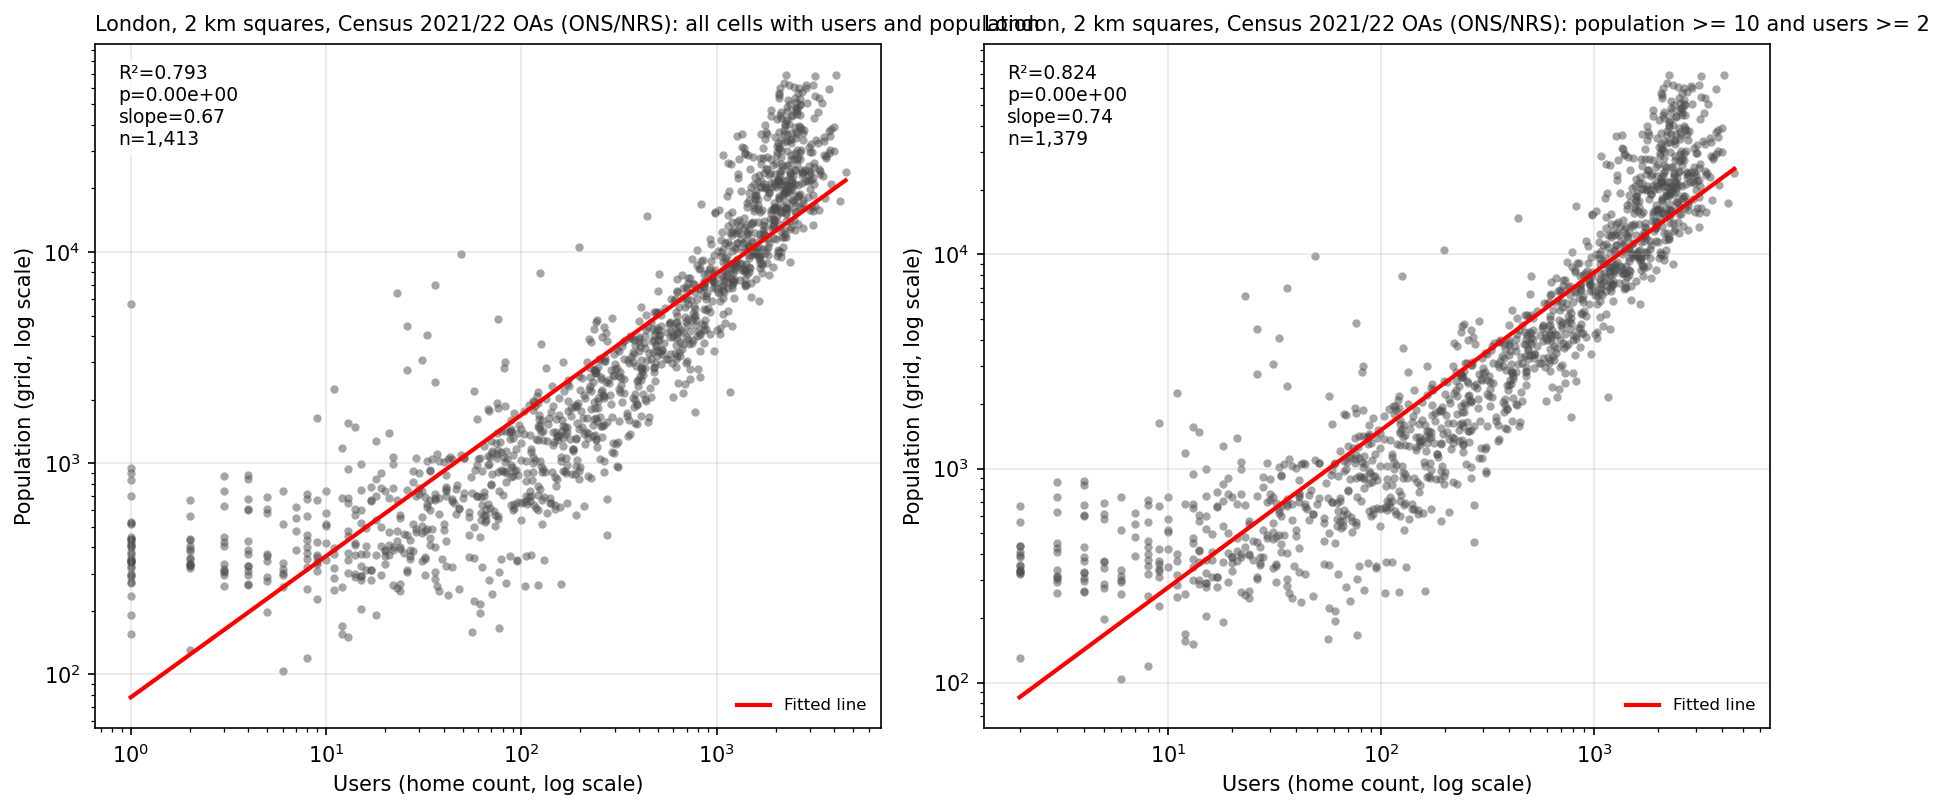

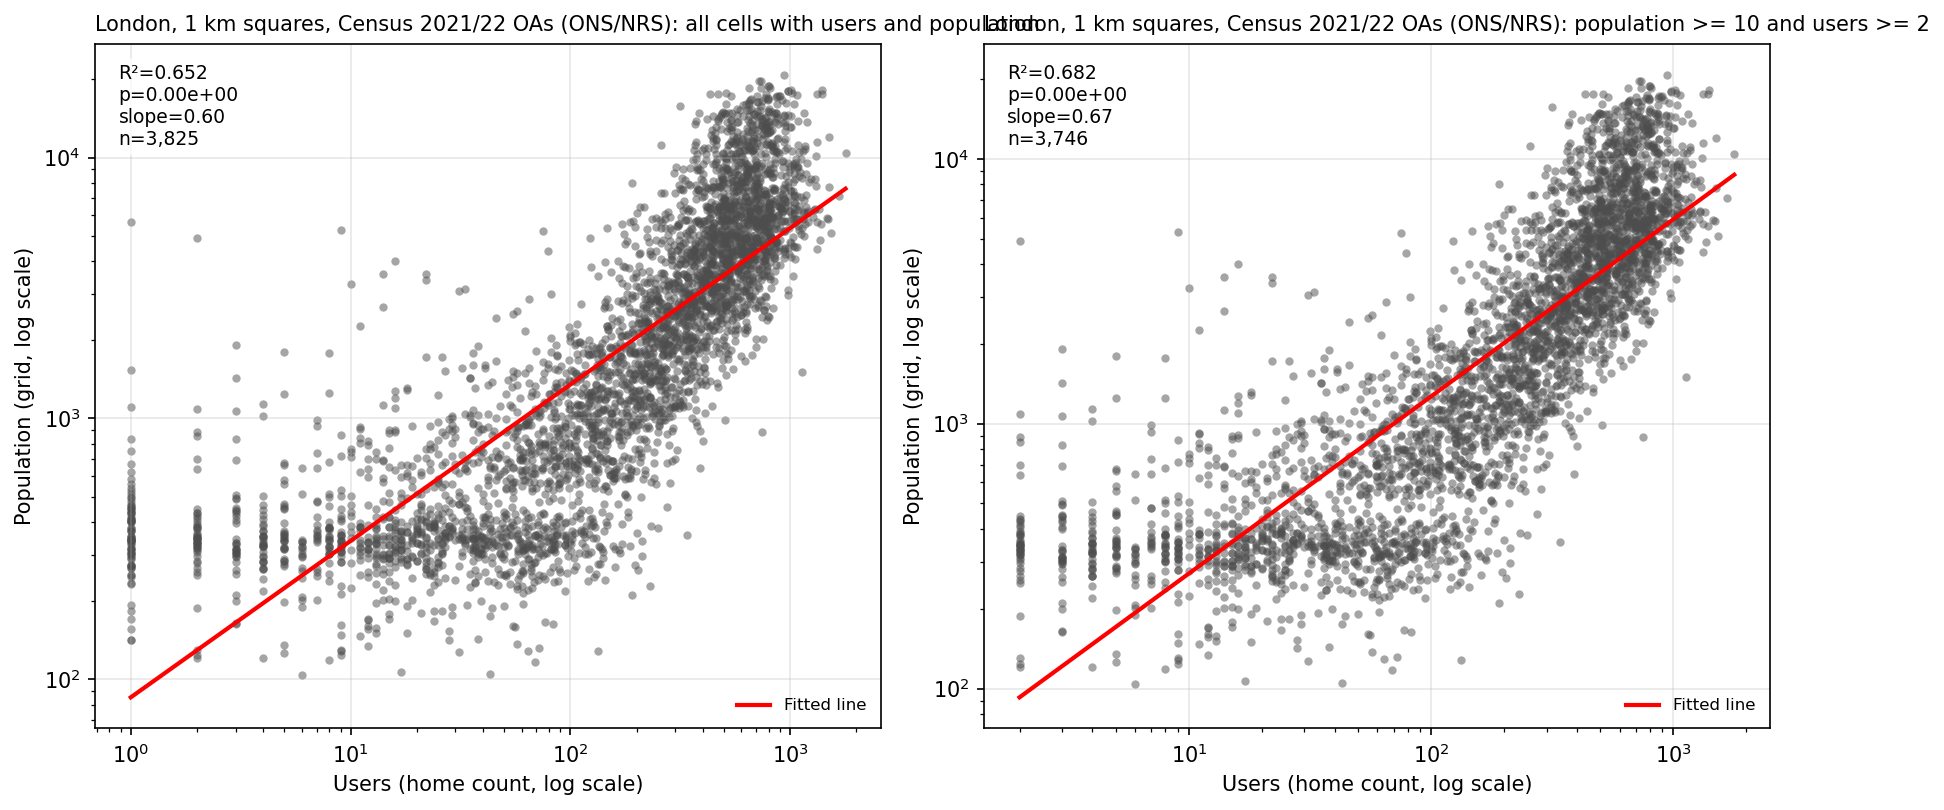

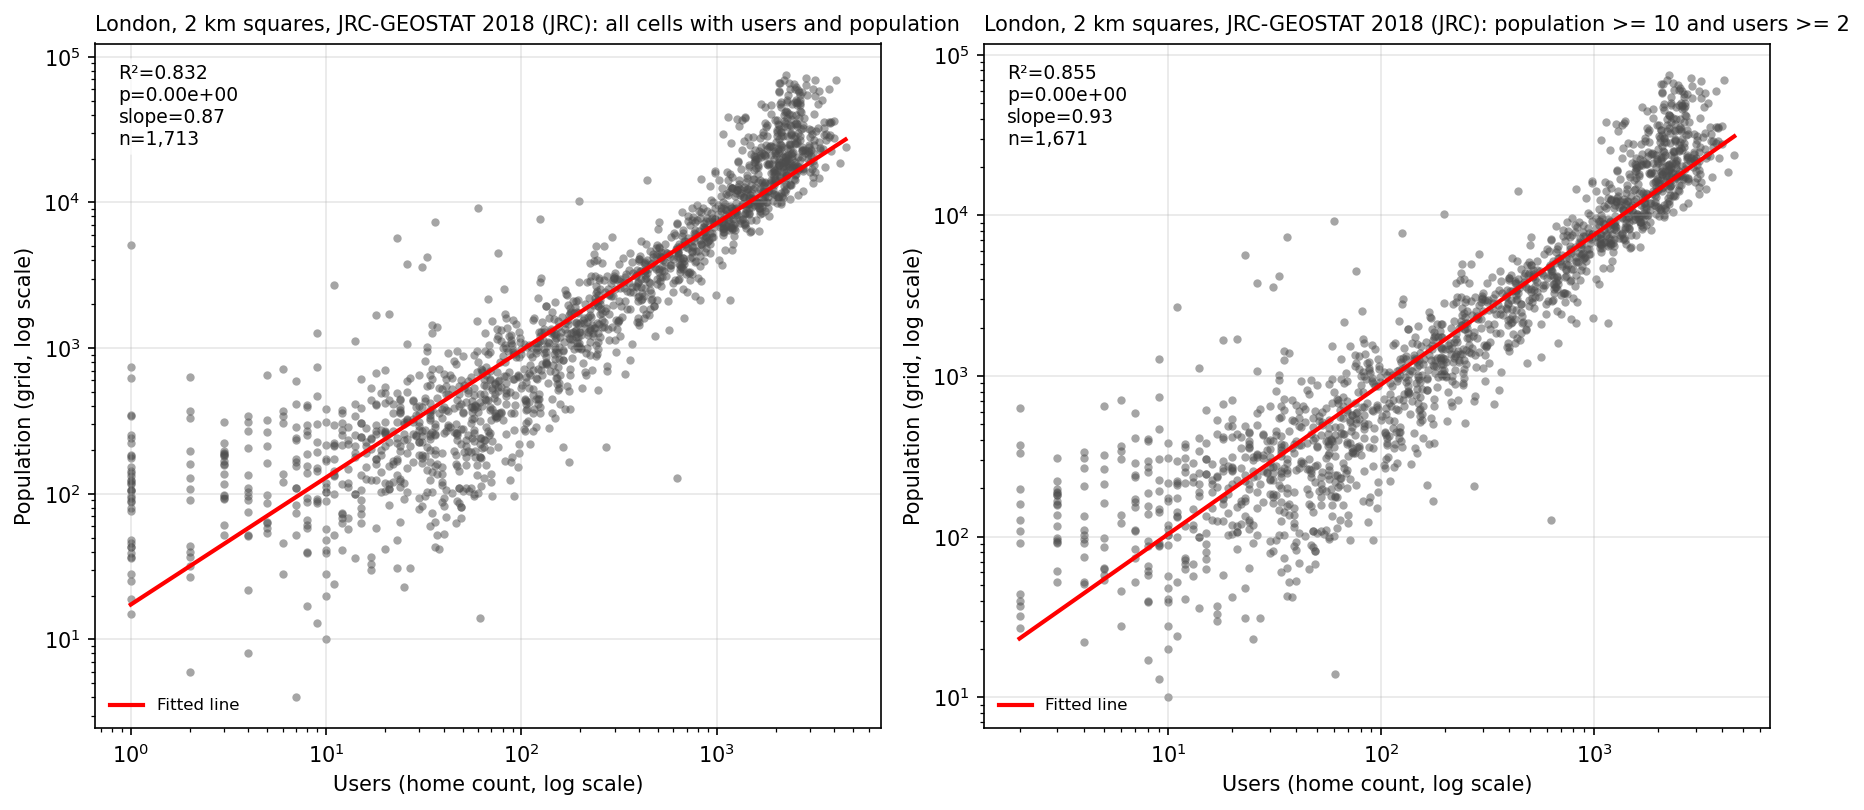

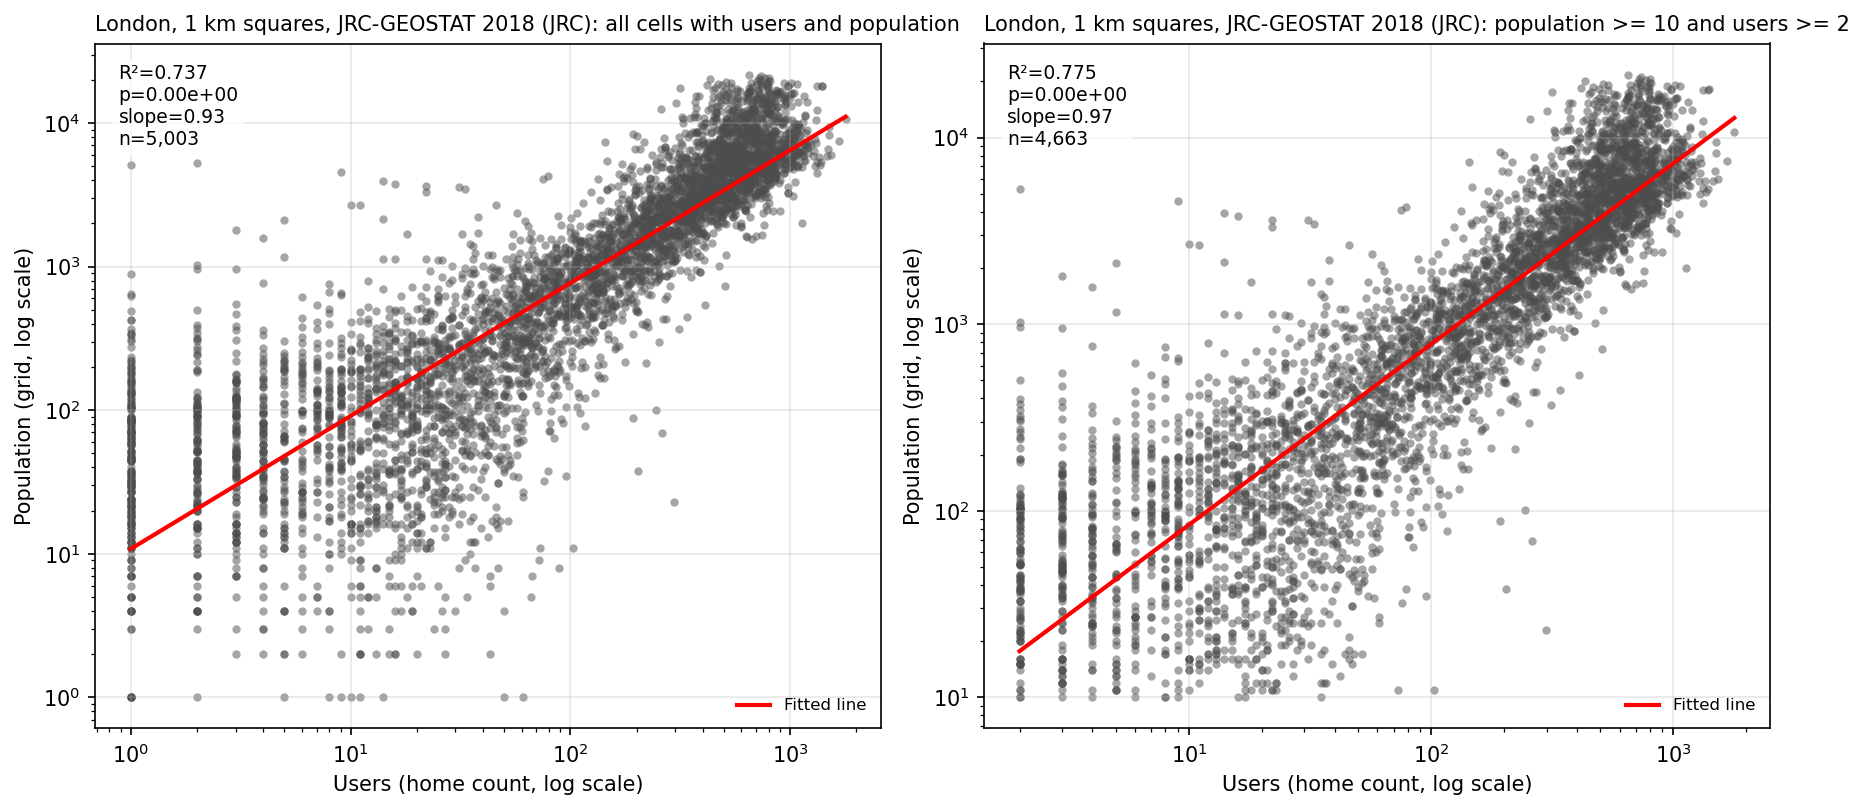

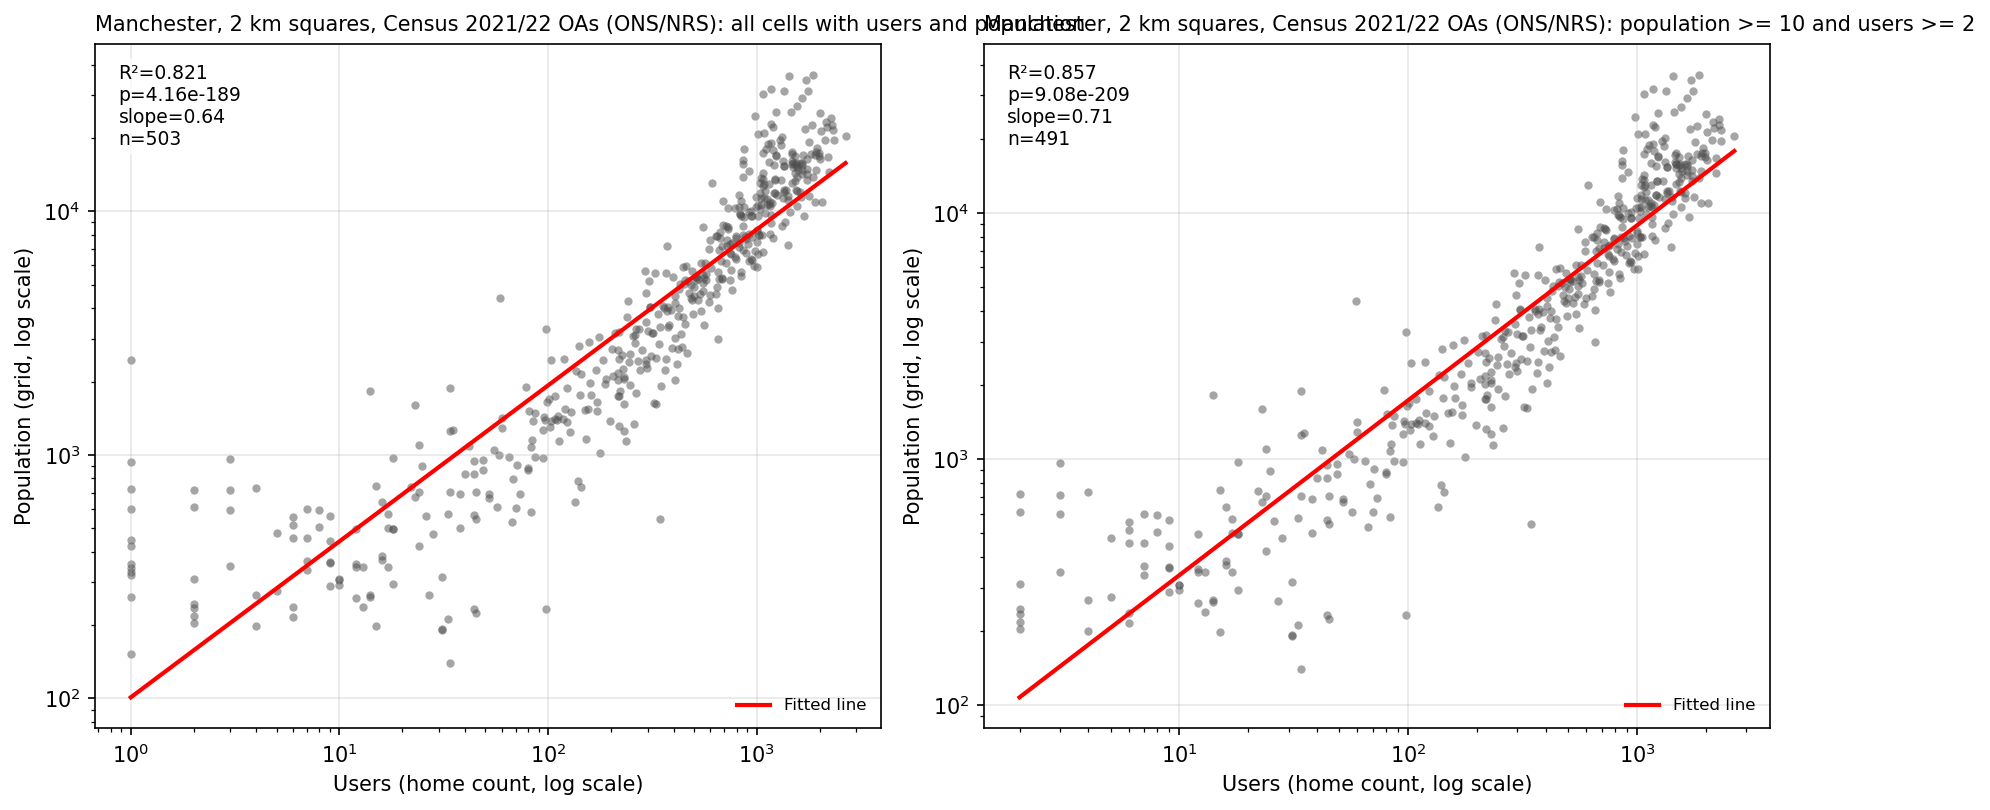

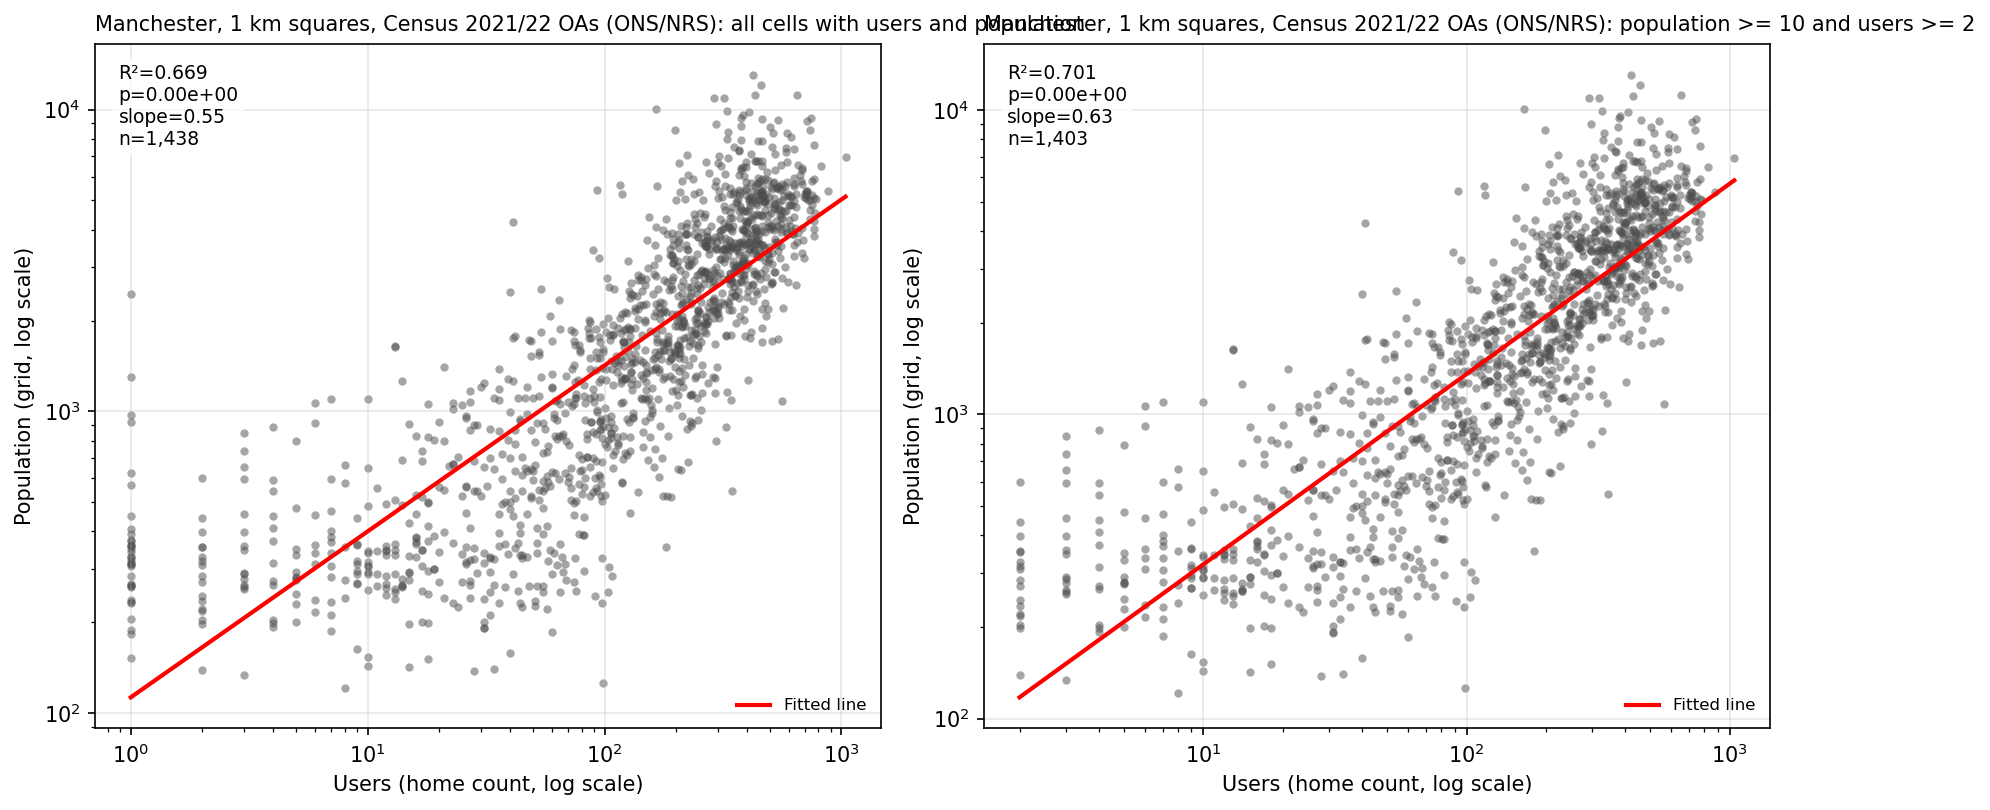

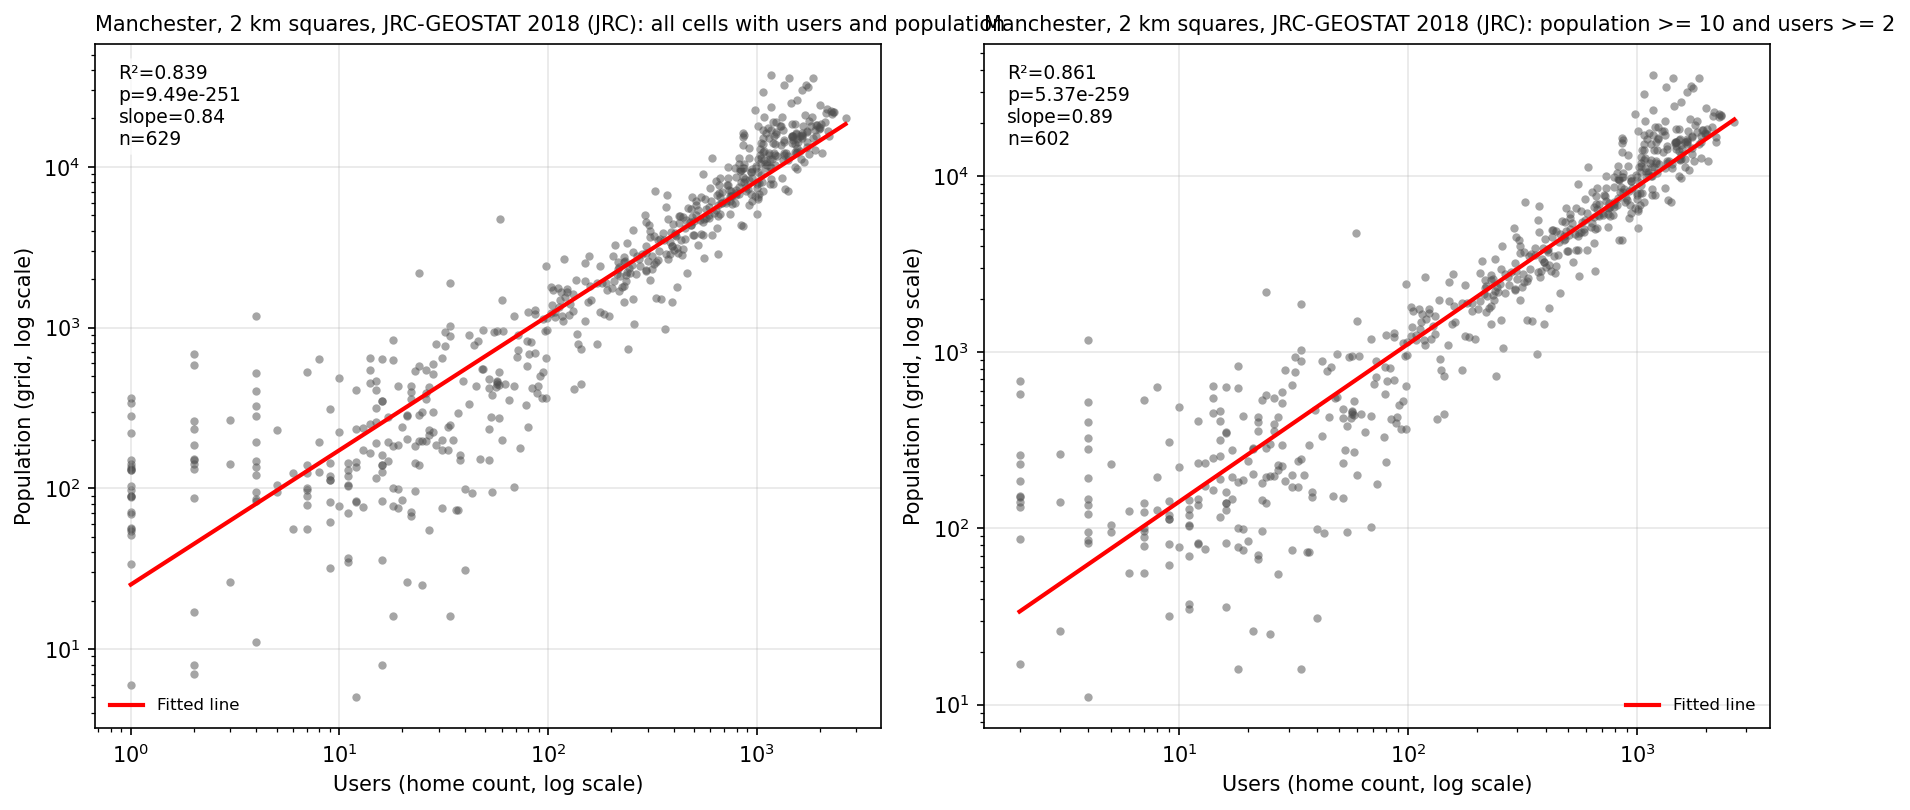

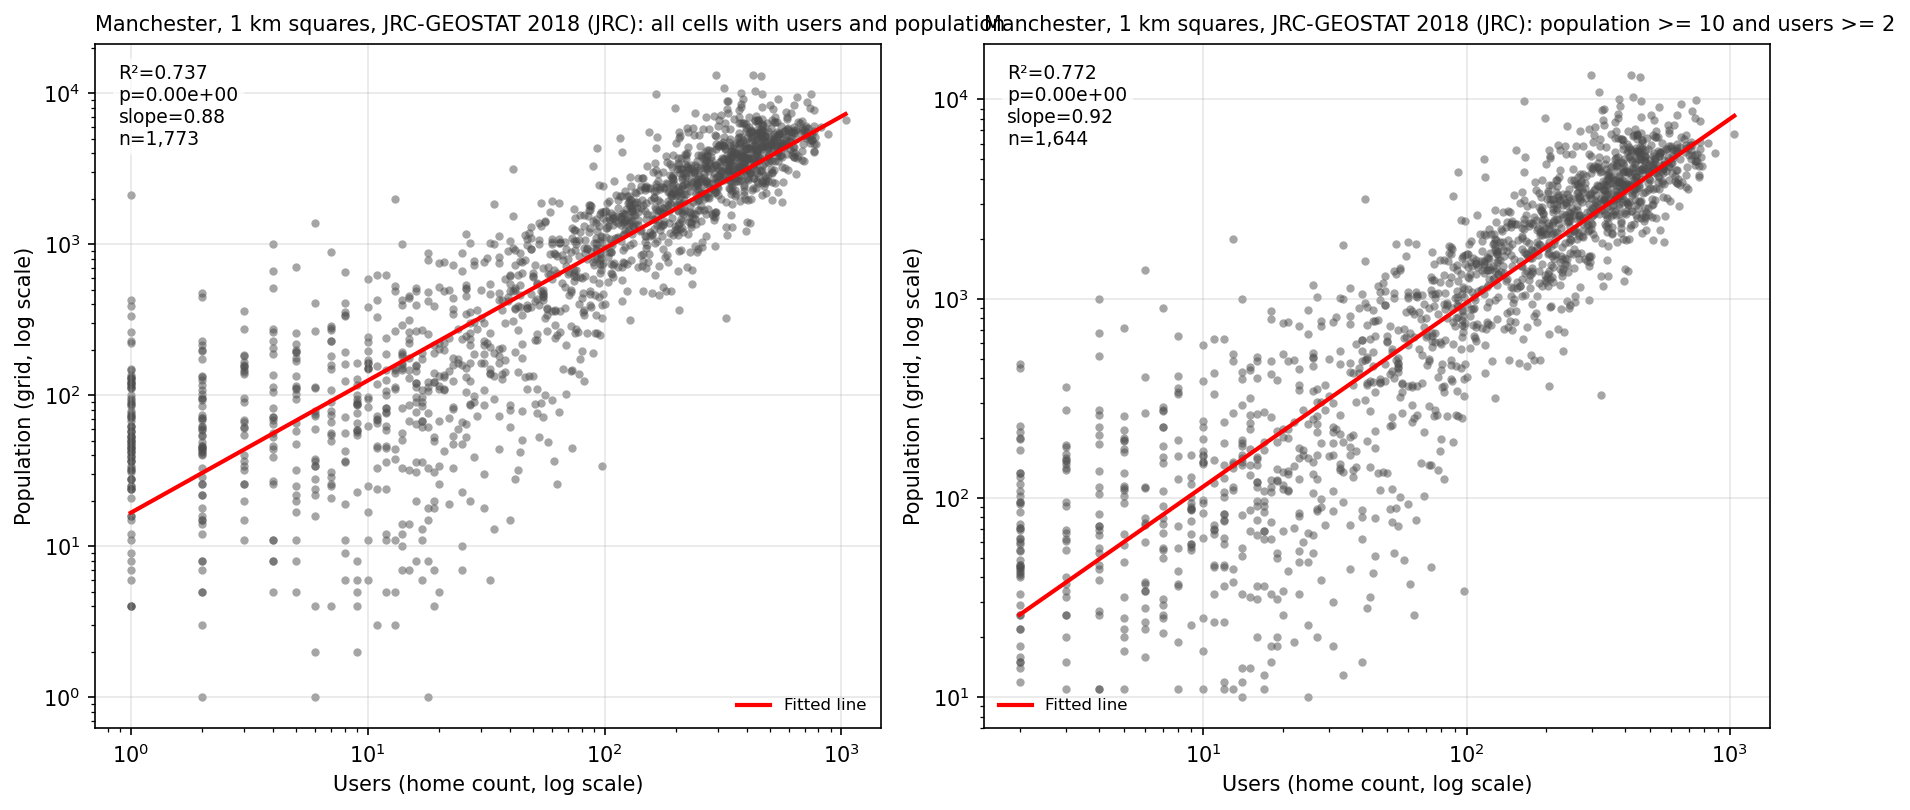

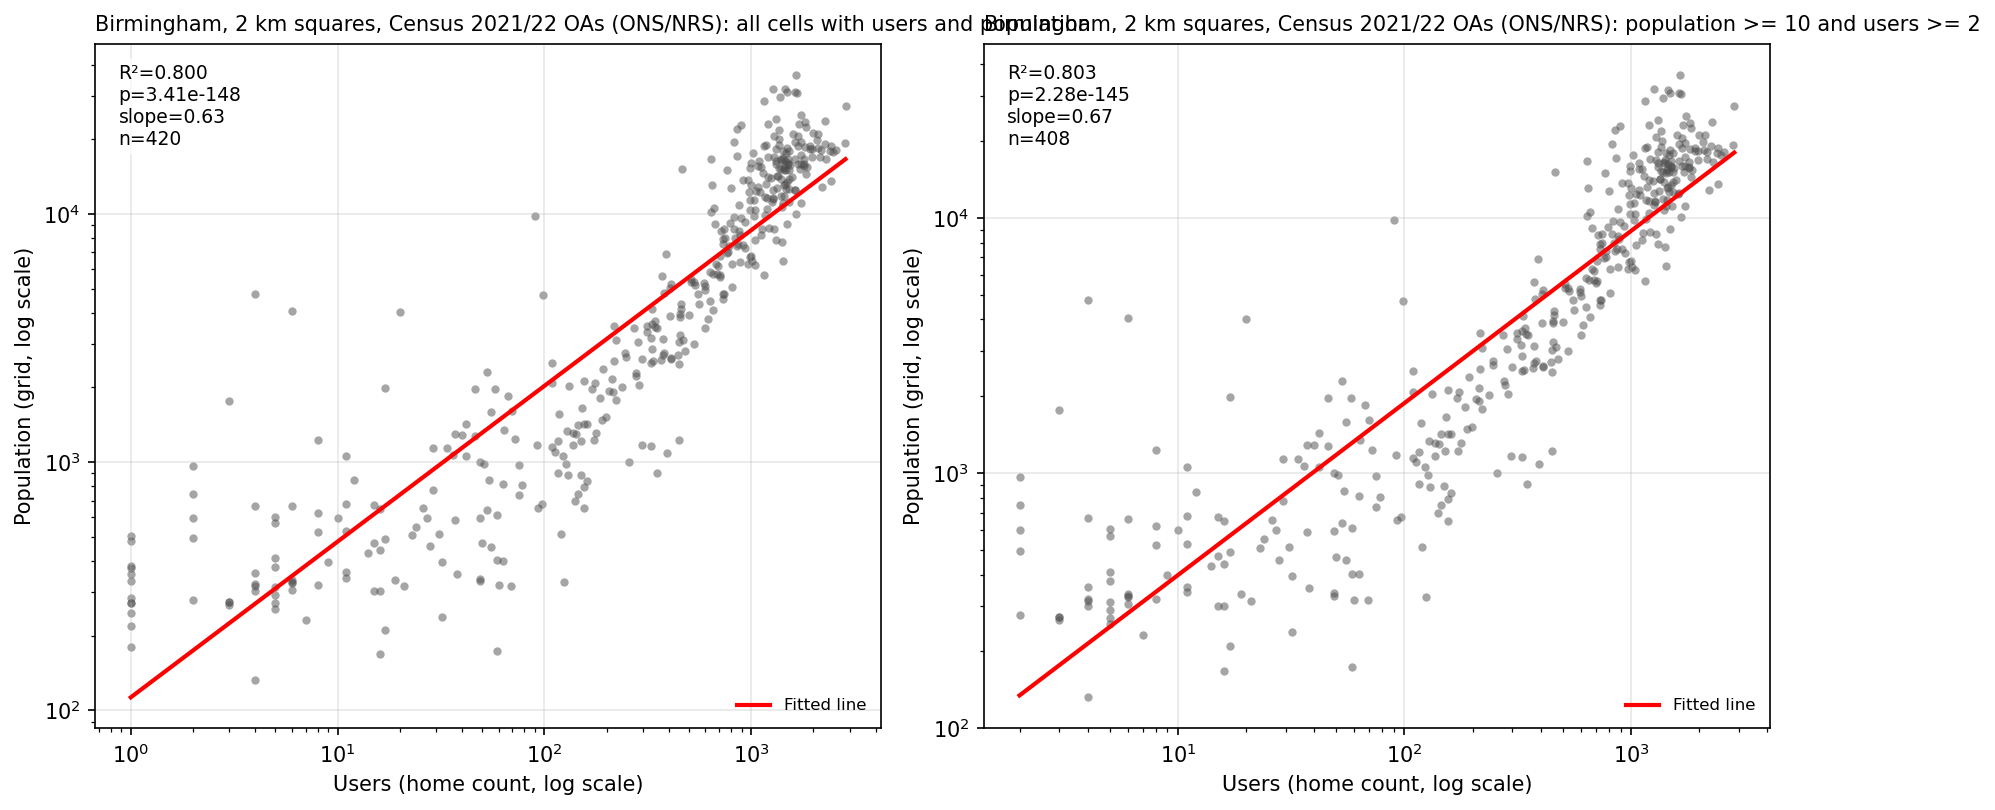

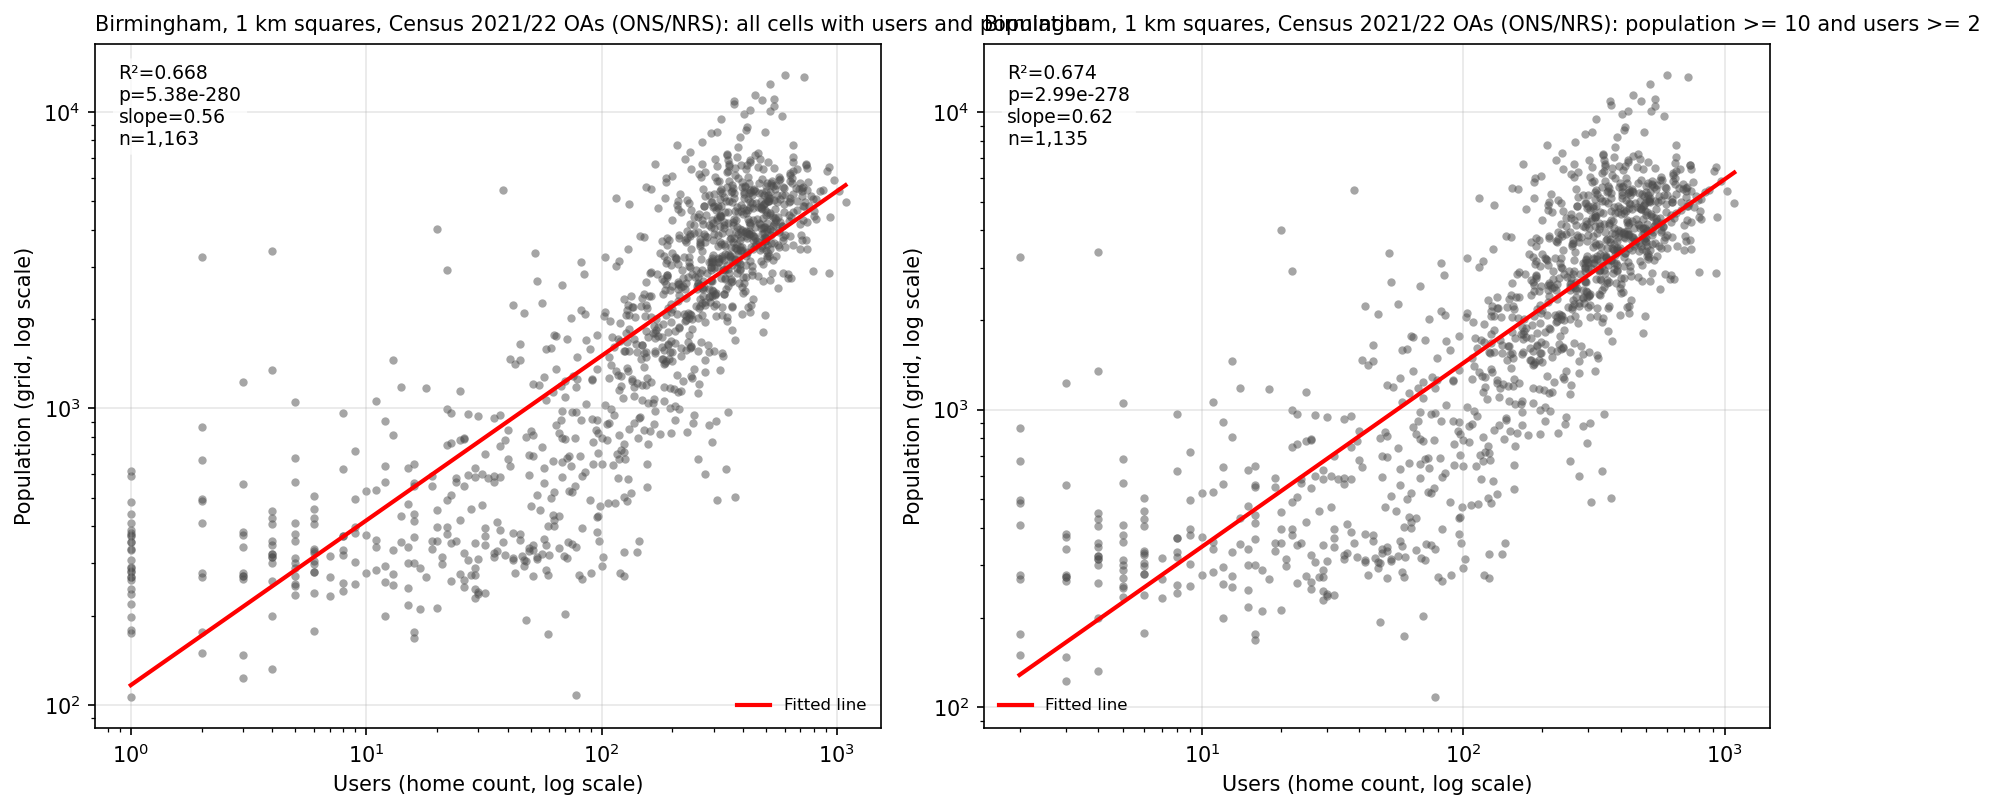

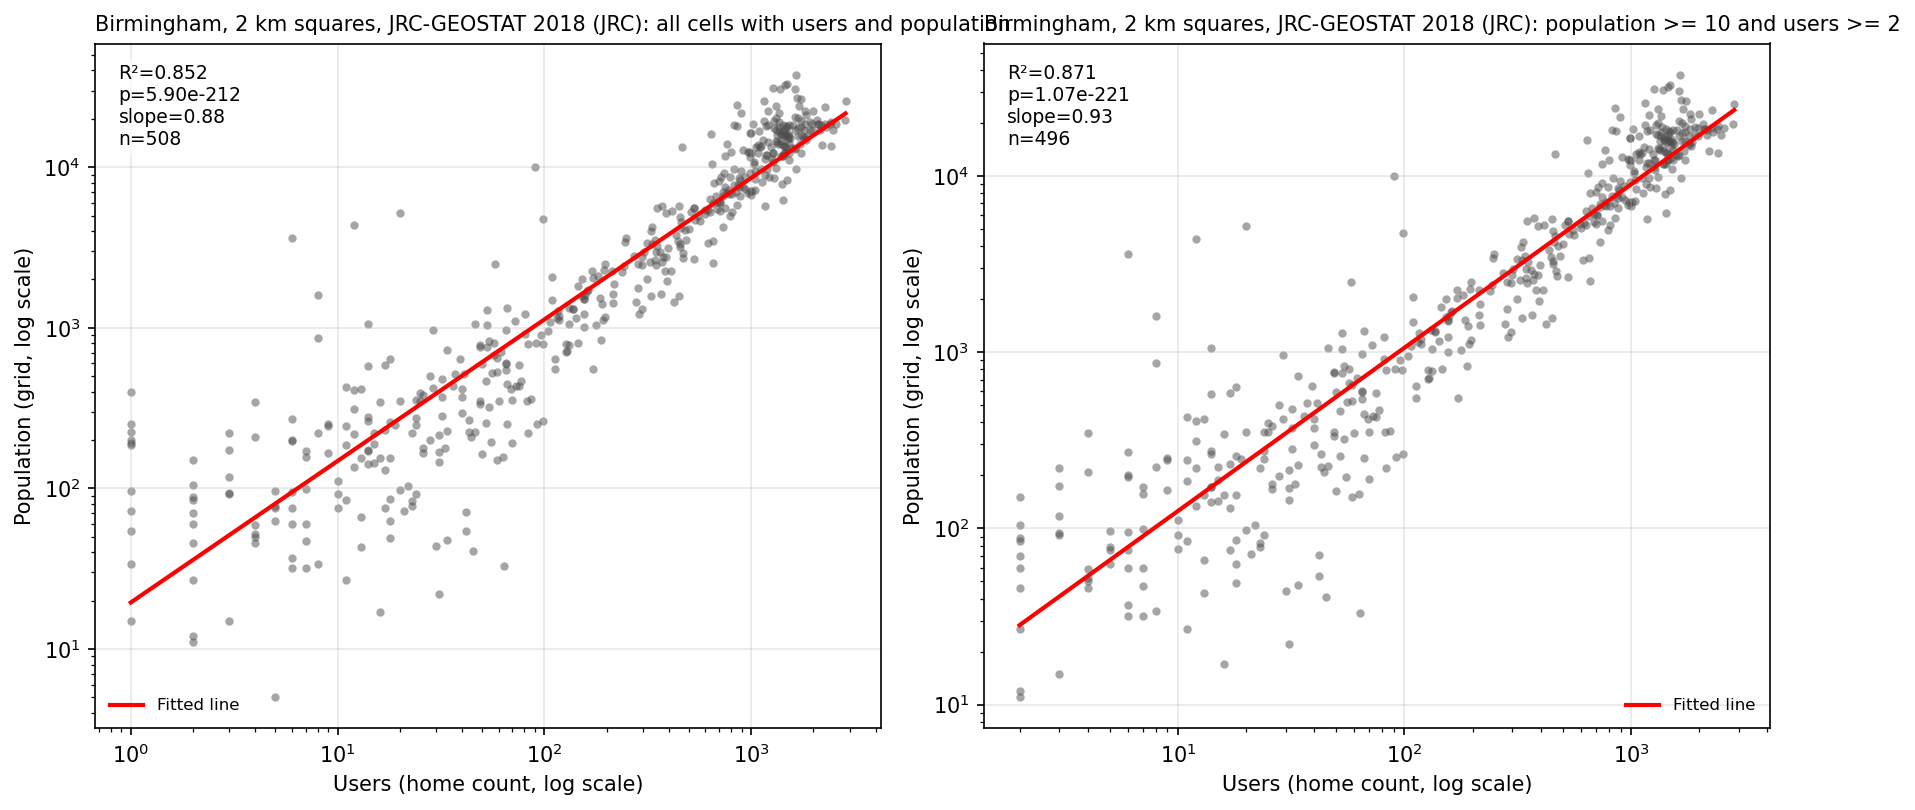

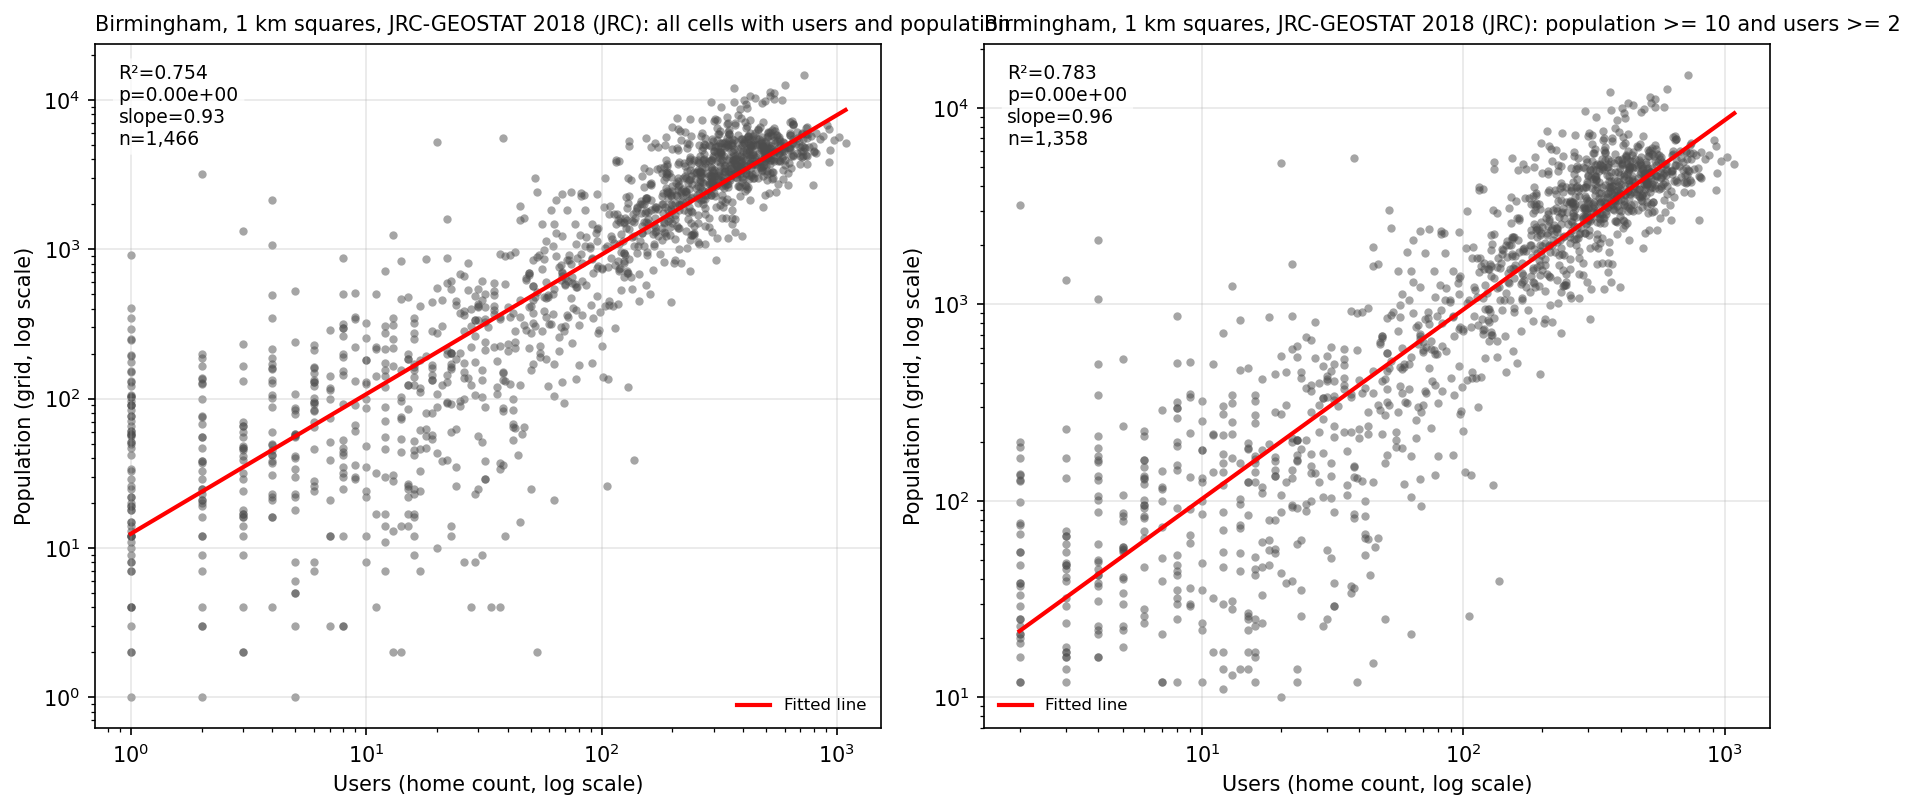

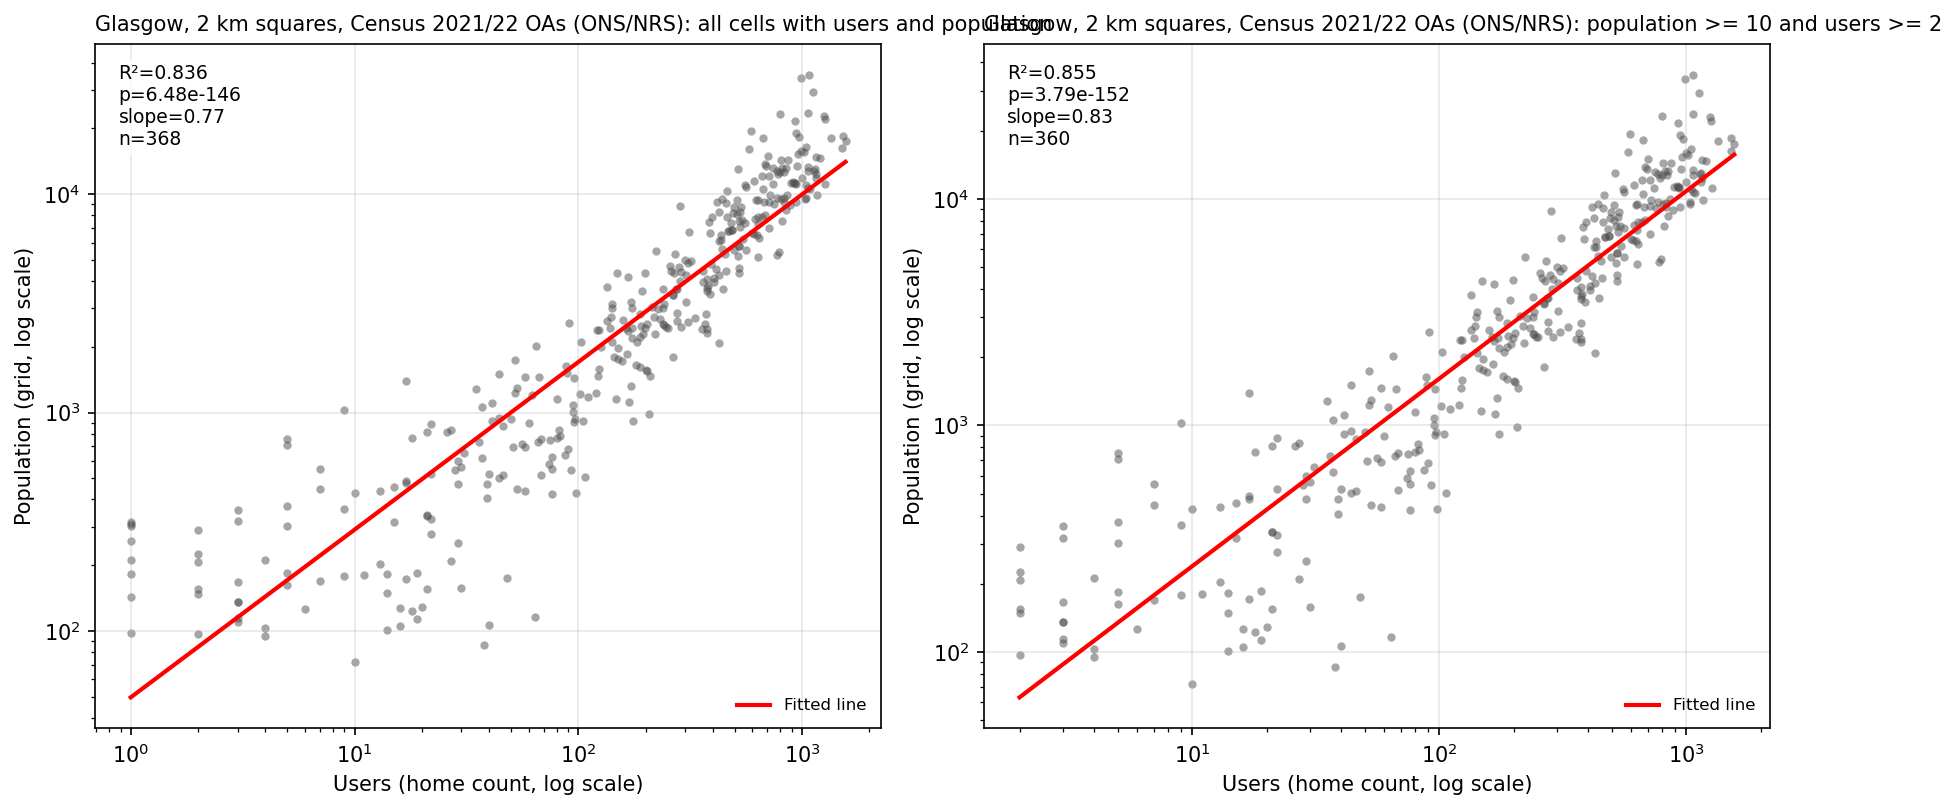

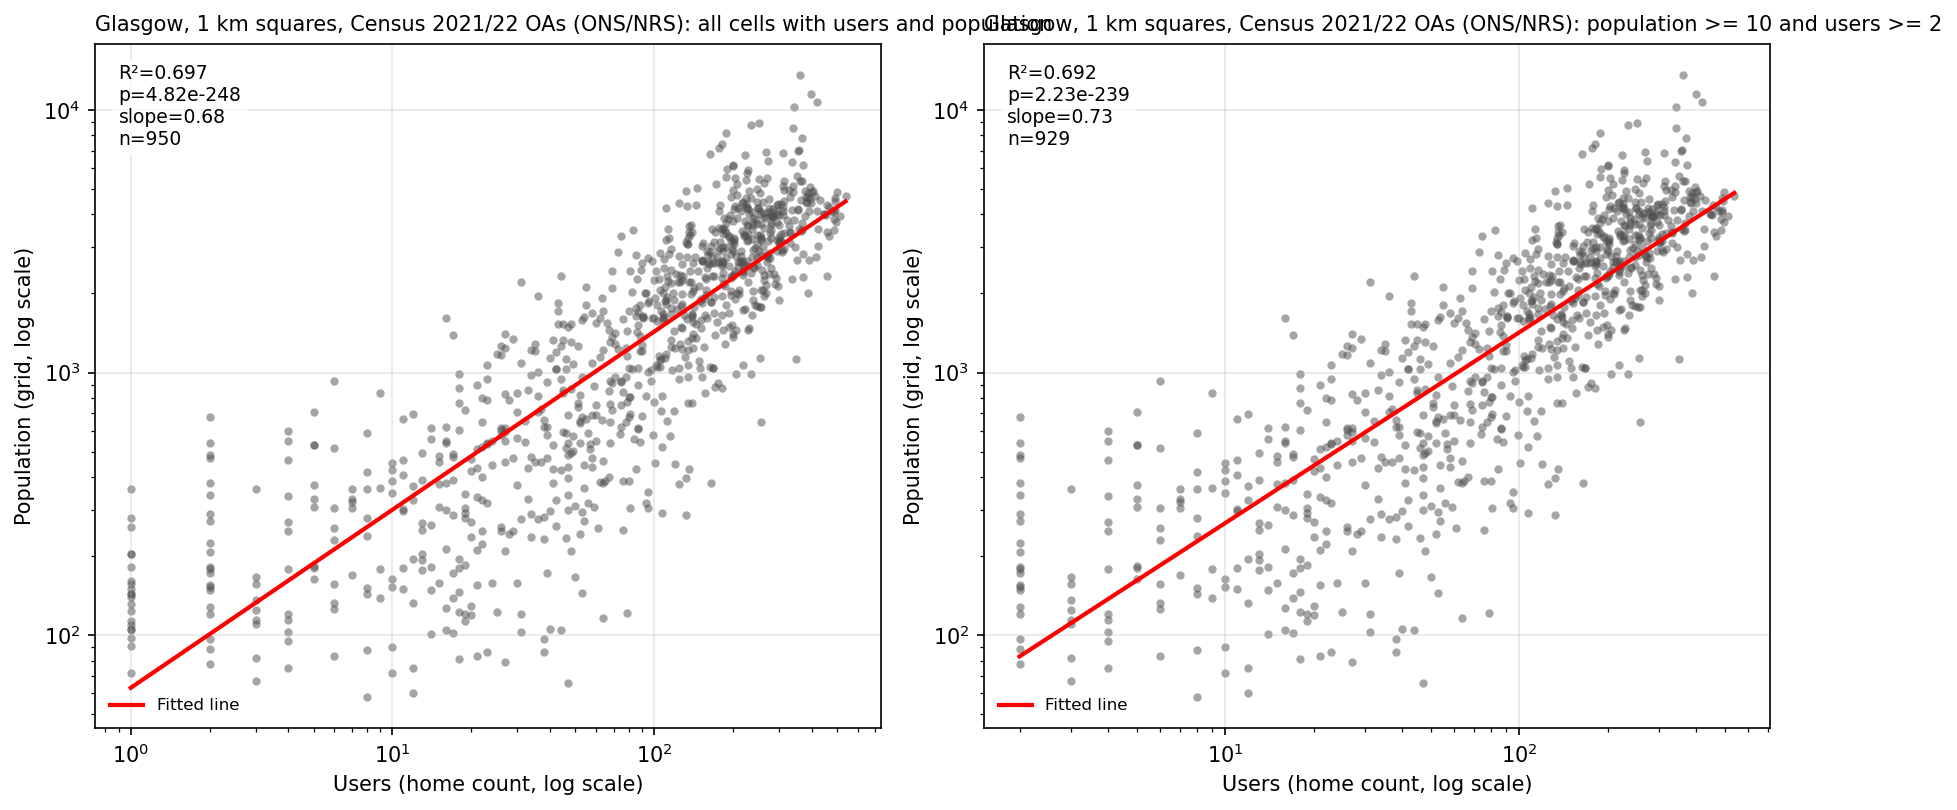

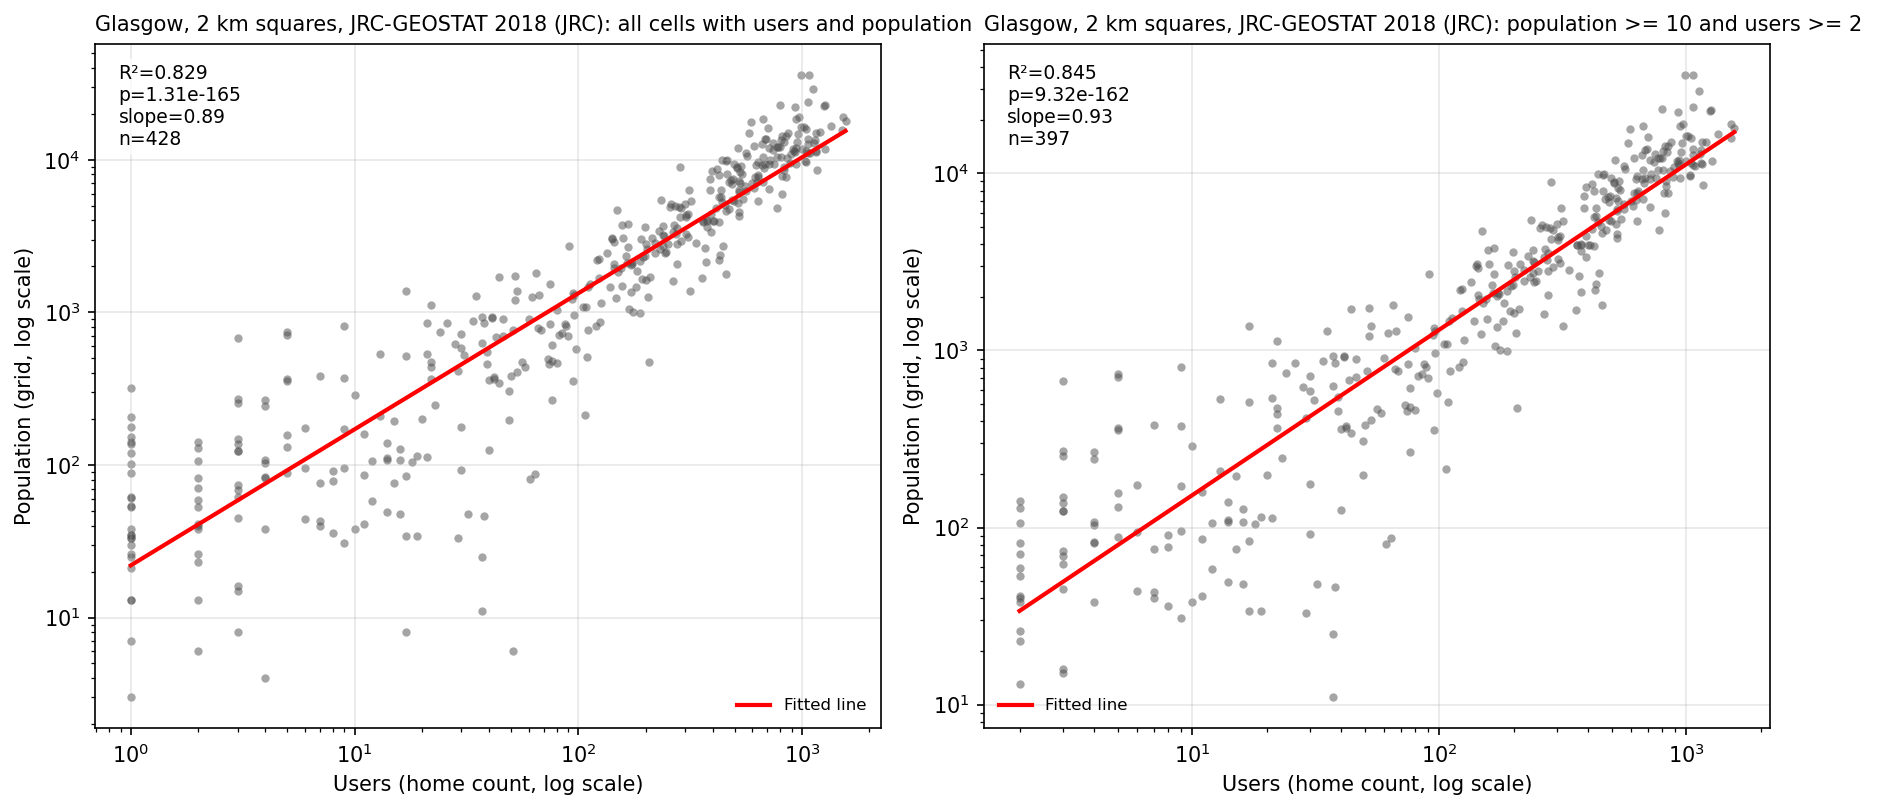

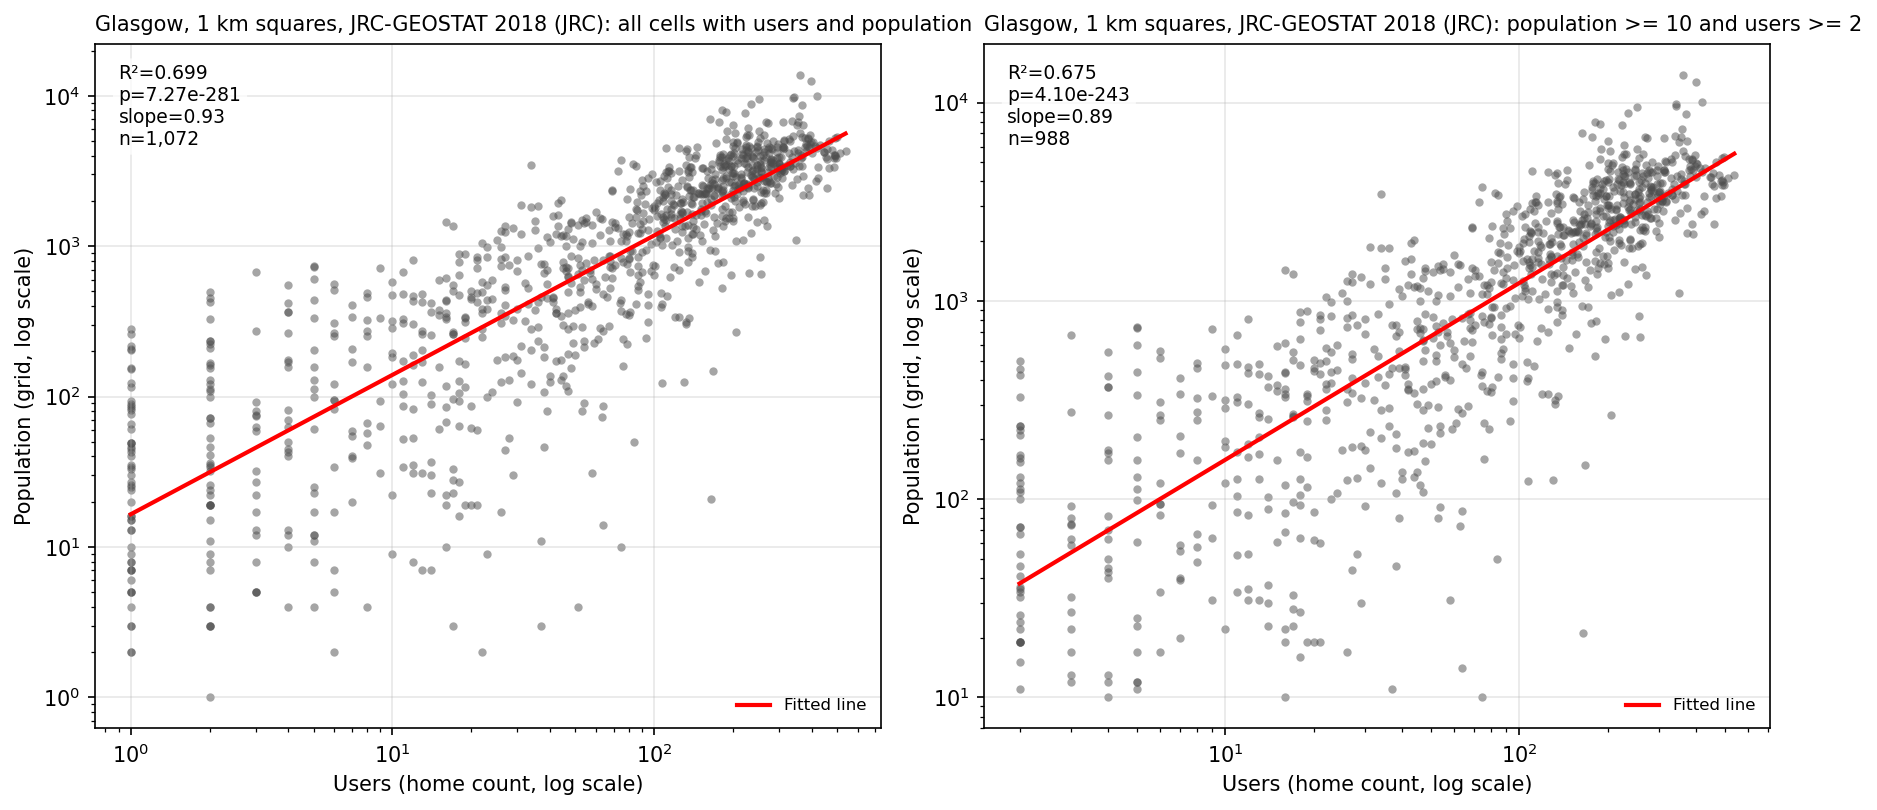

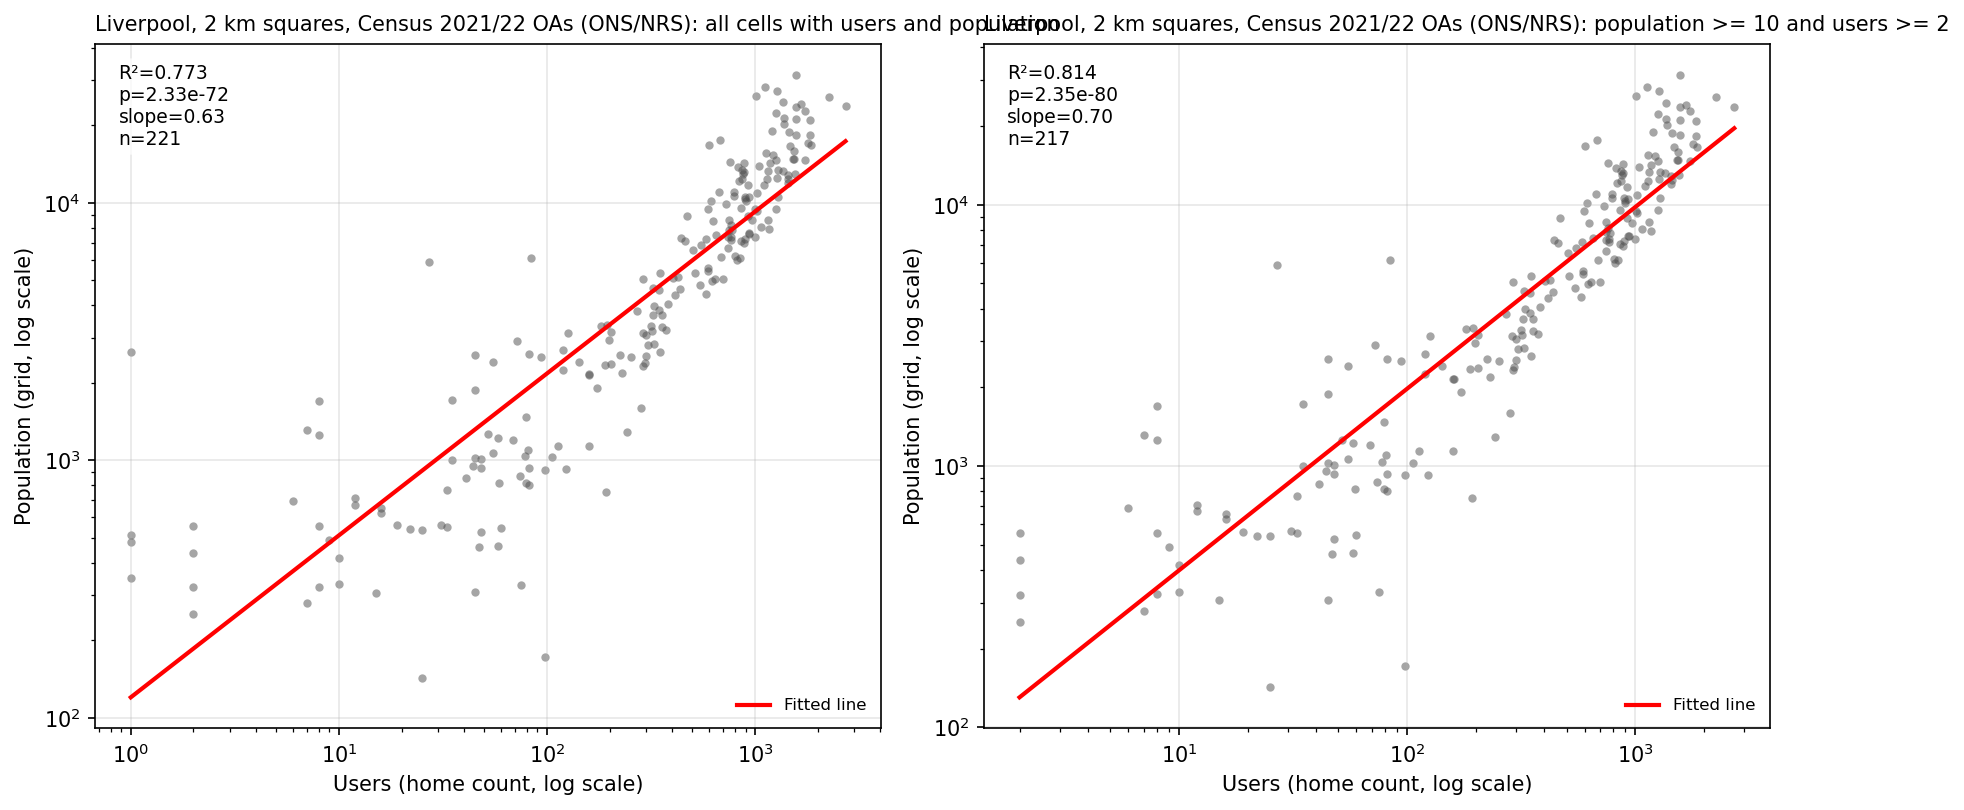

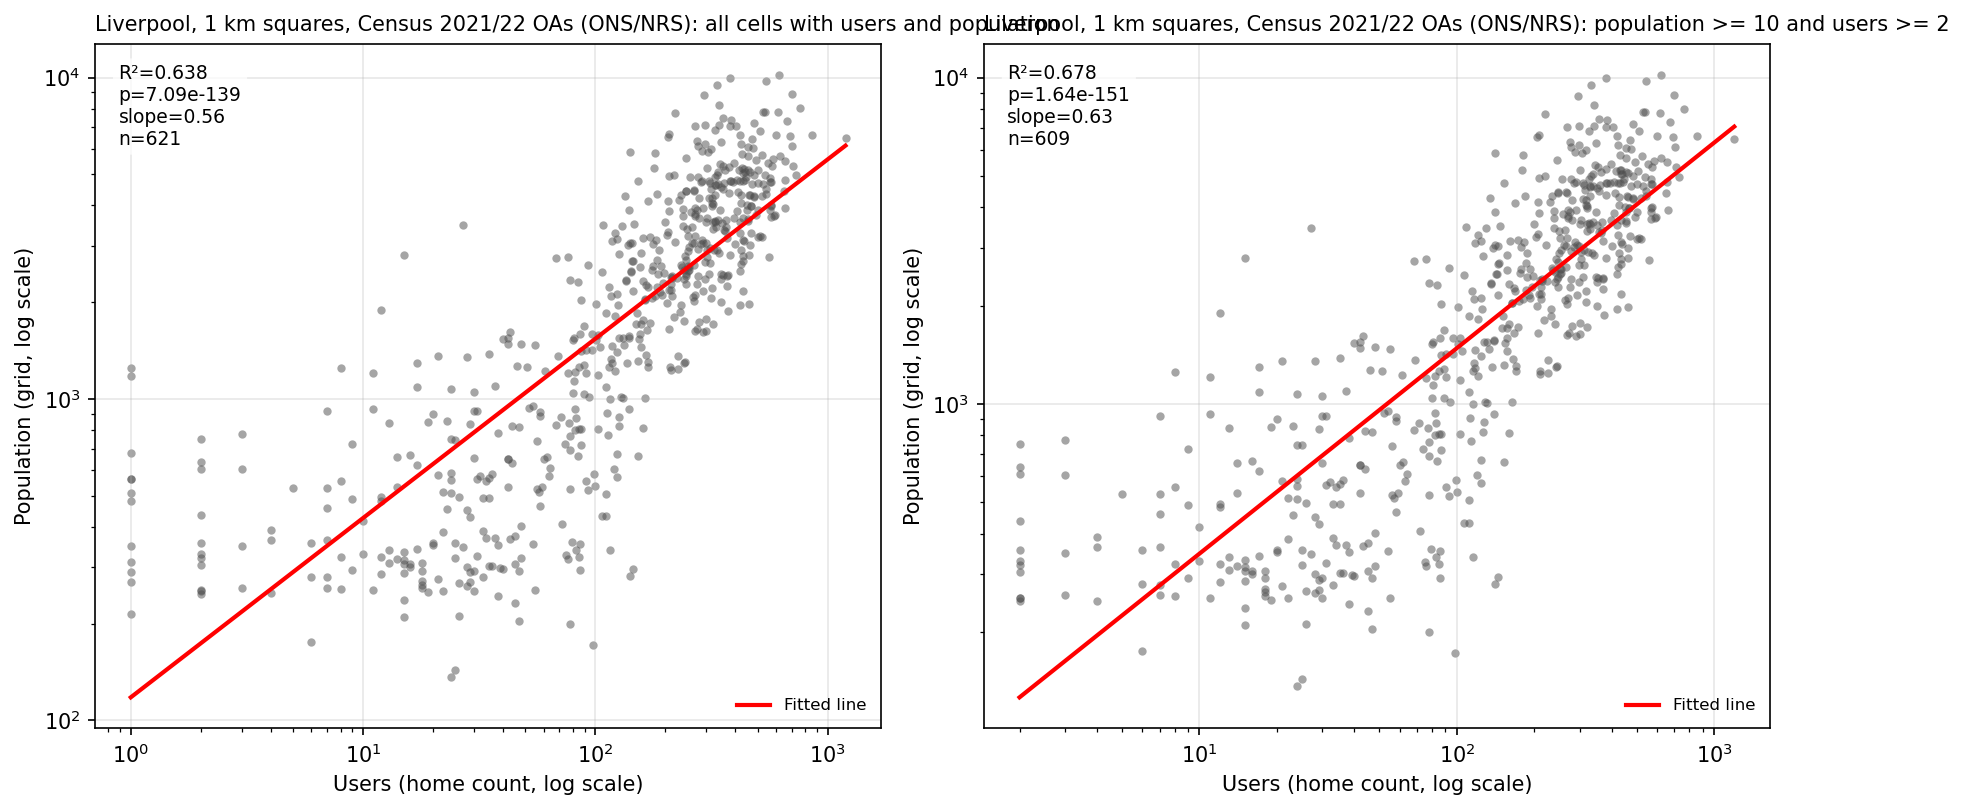

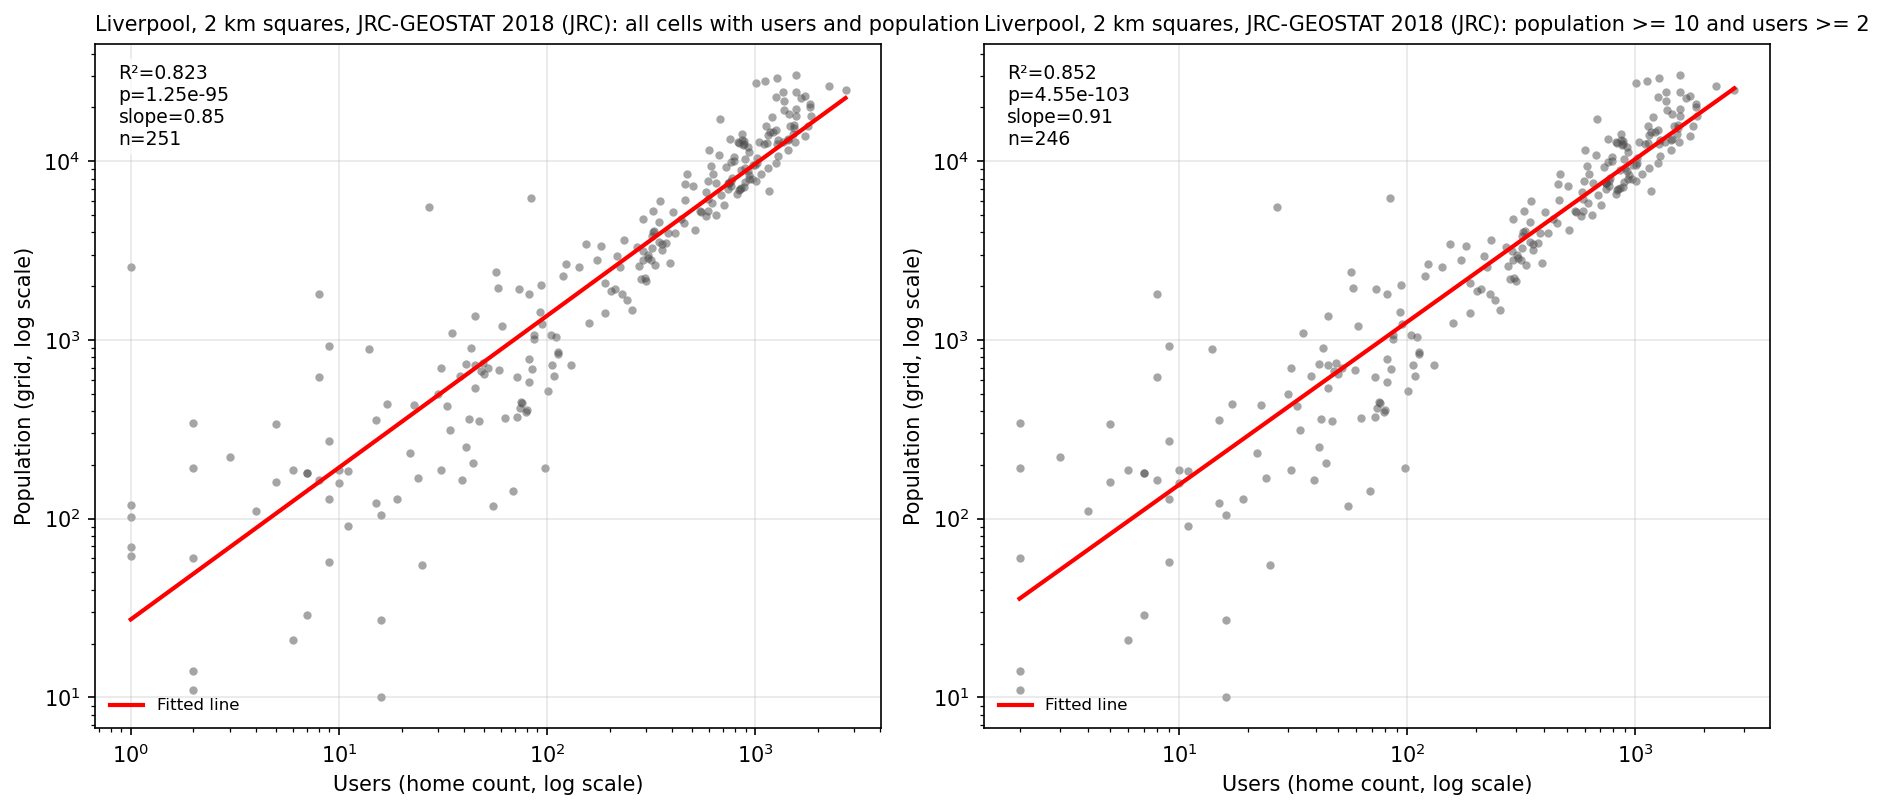

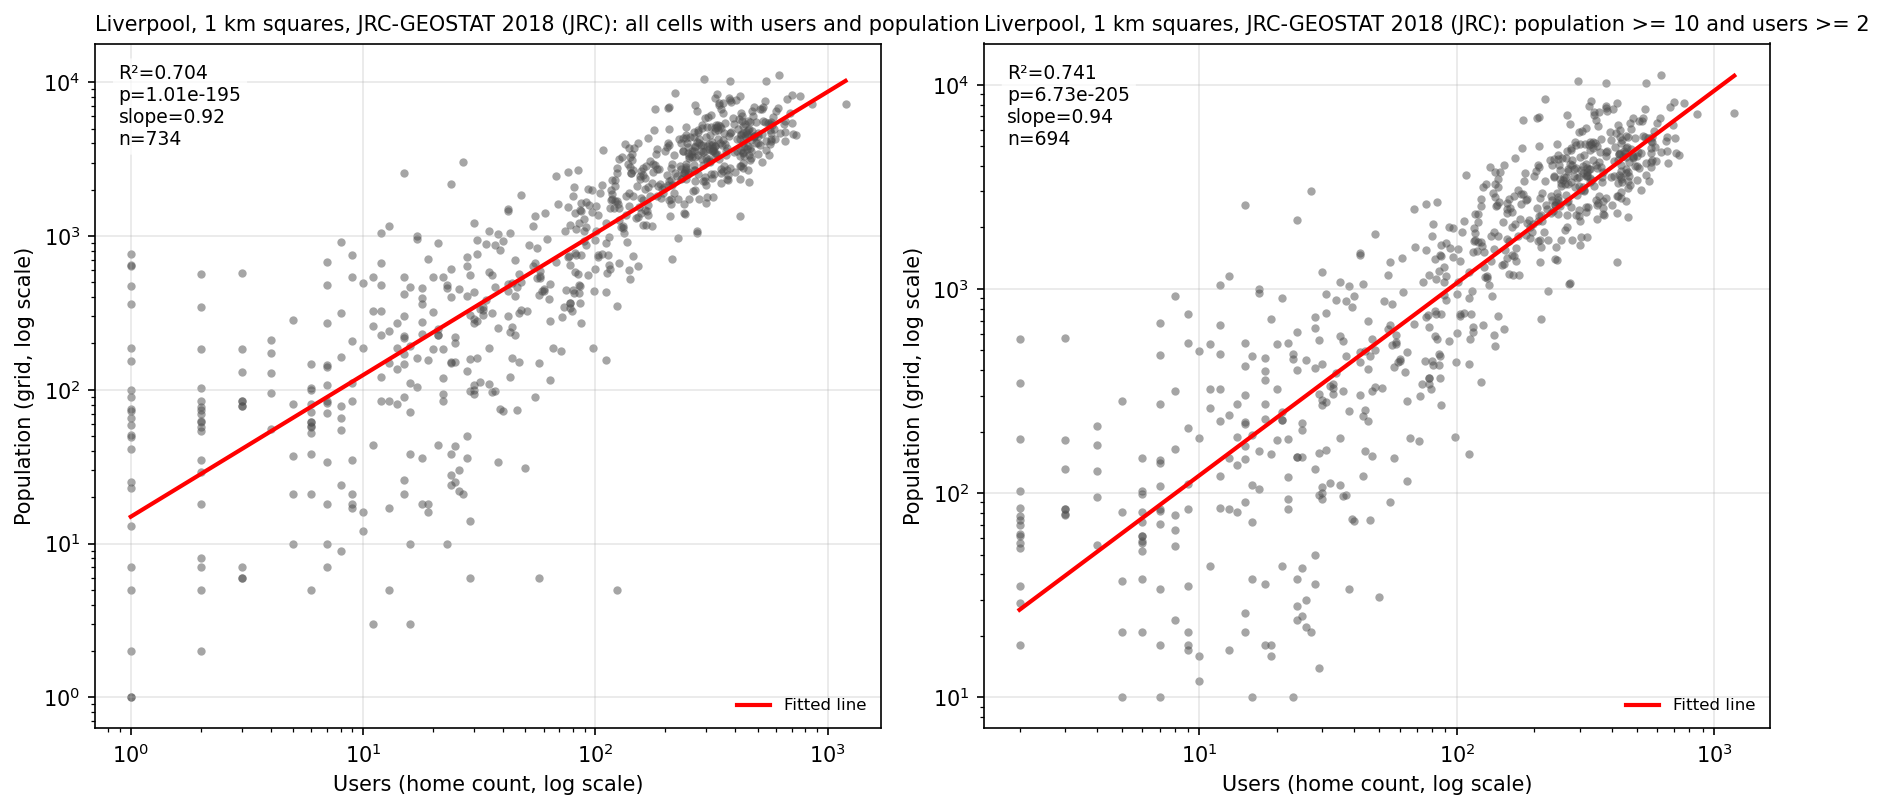

In [4]:
def loglog_panel(ax, g, title):
    lx, ly = np.log10(g.users_home_count.values), np.log10(g.population.values)
    res = linregress(lx, ly)
    ax.scatter(g.users_home_count, g.population, color="0.3", s=16, alpha=0.5, linewidths=0)
    ax.set_xscale("log"); ax.set_yscale("log")
    lx_line = np.linspace(lx.min(), lx.max(), 200)
    ax.plot(10 ** lx_line, 10 ** (res.intercept + res.slope * lx_line), color="red", lw=2, label="Fitted line")
    ax.text(0.03, 0.97, f"R²={res.rvalue**2:.3f}\np={res.pvalue:.2e}\nslope={res.slope:.2f}\nn={len(g):,}", transform=ax.transAxes, va="top", ha="left", fontsize=9,
            bbox=dict(boxstyle="round", fc="white", alpha=0.7, lw=0))
    ax.set_xlabel("Users (home count, log scale)"); ax.set_ylabel("Population (grid, log scale)"); ax.set_title(title, fontsize=10, loc="left")
    ax.grid(alpha=0.3); ax.legend(frameon=False, fontsize=8)
    return res

FITS = {}                           # FITS[key][source][km]
for key in CITY_KEYS:
    name = CITIES[key]["name"]; FITS[key] = {}
    for source in sources_of(key):
        FITS[key][source] = {}
        for km in UNITS:
            g = G[key][source][km]
            g_all = g.query("users_home_count > 0 and population > 0")
            g_5   = g.query(f"population >= {POP_MIN} and users_home_count >= {USERS_MIN}")
            fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), dpi=FIGURE_DPI)
            FITS[key][source][km] = {"all": loglog_panel(axes[0], g_all, f"{name}, {km} km squares, {source}: all cells with users and population"),
                                     "pop>=5": loglog_panel(axes[1], g_5, f"{name}, {km} km squares, {source}: population >= {POP_MIN} and users >= {USERS_MIN}")}
            plt.tight_layout(); plt.show()

## 4. Penetration per grid cell and summary

In [5]:
def poisson_ceiling(g, n_sim=20, seed=0):
    """R² (filtered fit) that a perfectly proportional sample of the same size would give: users ~ Poisson(penetration x population)"""
    rng = np.random.default_rng(seed); p = g.population.values.astype(float); pen = g.users_home_count.sum() / p.sum(); out = []
    for _ in range(n_sim):
        u = rng.poisson(pen * p).astype(float); m = (p >= POP_MIN) & (u >= USERS_MIN)
        out.append(linregress(np.log10(u[m]), np.log10(p[m])).rvalue ** 2)
    return float(np.mean(out))

rows = []
for key in CITY_KEYS:
  for source in sources_of(key):
    for km in UNITS:
        g = G[key][source][km]; g5 = g.query(f"population >= {POP_MIN} and users_home_count >= {USERS_MIN}").copy(); g5["penetration"] = g5.users_home_count / g5.population
        f_all, f_5 = FITS[key][source][km]["all"], FITS[key][source][km]["pop>=5"]
        rows.append({"city": CITIES[key]["name"], "unit (km)": km, "population source": source,
                     "grid population (cells of the FUA)": int(g.population.sum()), "sample users": int(g.users_home_count.sum()),
                     "overall penetration %": 100 * g.users_home_count.sum() / g.population.sum(),
                     "grid cells with population": int((g.population > 0).sum()), "grid cells with users": int((g.users_home_count > 0).sum()),
                     "population in cells without users %": 100 * g.loc[g.users_home_count == 0, "population"].sum() / g.population.sum(),
                     "R² all cells": f_all.rvalue ** 2, "slope all cells": f_all.slope,
                     f"R² pop>={POP_MIN} & users>={USERS_MIN}": f_5.rvalue ** 2, f"slope pop>={POP_MIN} & users>={USERS_MIN}": f_5.slope, f"n cells pop>={POP_MIN} & users>={USERS_MIN}": len(g5),
                     "R² ceiling of a proportional Poisson sample": poisson_ceiling(g),
                     f"mean penetration (pop>={POP_MIN} & users>={USERS_MIN})": g5.penetration.mean(), f"median penetration (pop>={POP_MIN} & users>={USERS_MIN})": g5.penetration.median()})
summary = pd.DataFrame(rows).set_index(["city", "unit (km)", "population source"])
summary.round(4).T

city                                                              London  \
unit (km)                                                              2   
population source                           Census 2021/22 OAs (ONS/NRS)   
grid population (cells of the FUA)                          1.257719e+07   
sample users                                                1.216967e+06   
overall penetration %                                       9.676000e+00   
grid cells with population                                  1.600000e+03   
grid cells with users                                       1.413000e+03   
population in cells without users %                         5.822000e-01   
R² all cells                                                7.930000e-01   
slope all cells                                             6.690000e-01   
R² pop>=10 & users>=2                                       8.239000e-01   
slope pop>=10 & users>=2                                    7.352000e-01   
n cells pop>=10 & users>=2                                  1.379000e+03   
R² ceiling of a proportional Poisson sample                 9.954000e-01   
mean penetration (pop>=10 & users>=2)                       1.122000e-01   
median penetration (pop>=10 & users>=2)                     1.040000e-01   

city                                                                      \
unit (km)                                                              1   
population source                           Census 2021/22 OAs (ONS/NRS)   
grid population (cells of the FUA)                          1.257719e+07   
sample users                                                1.216967e+06   
overall penetration %                                       9.676000e+00   
grid cells with population                                  4.289000e+03   
grid cells with users                                       3.825000e+03   
population in cells without users %                         1.422300e+00   
R² all cells                                                6.520000e-01   
slope all cells                                             5.996000e-01   
R² pop>=10 & users>=2                                       6.821000e-01   
slope pop>=10 & users>=2                                    6.687000e-01   
n cells pop>=10 & users>=2                                  3.746000e+03   
R² ceiling of a proportional Poisson sample                 9.907000e-01   
mean penetration (pop>=10 & users>=2)                       1.227000e-01   
median penetration (pop>=10 & users>=2)                     1.043000e-01   

city                                                                \
unit (km)                                                        2   
population source                           JRC-GEOSTAT 2018 (JRC)   
grid population (cells of the FUA)                    1.251276e+07   
sample users                                          1.240574e+06   
overall penetration %                                 9.914500e+00   
grid cells with population                            1.884000e+03   
grid cells with users                                 1.713000e+03   
population in cells without users %                   1.464000e-01   
R² all cells                                          8.322000e-01   
slope all cells                                       8.727000e-01   
R² pop>=10 & users>=2                                 8.555000e-01   
slope pop>=10 & users>=2                              9.313000e-01   
n cells pop>=10 & users>=2                            1.671000e+03   
R² ceiling of a proportional Poisson sample           9.915000e-01   
mean penetration (pop>=10 & users>=2)                 1.563000e-01   
median penetration (pop>=10 & users>=2)               1.261000e-01   

city                                                                \
unit (km)                                                        1   
population source                           JRC-GEOSTAT 2018 (JRC)   
grid populati

In [6]:
# Robustness: the log-log fit under stricter cuts on small counts, each against the R² a proportional Poisson sample would give
CUTS = {"all cells (users > 0, pop > 0)": (1, 1), "pop >= 5, users >= 1 (Finnish paper)": (5, 1), "pop >= 10, users >= 2 (headline)": (10, 2),
        "pop >= 50, users >= 5": (50, 5), "pop >= 100, users >= 10": (100, 10)}

def fit_r2(u, p, pm, um):
    m = (p >= pm) & (u >= um); res = linregress(np.log10(u[m]), np.log10(p[m])); return res.rvalue ** 2, res.slope, int(m.sum())

def ceiling(p, pen, pm, um, n_sim=20, seed=0):
    rng = np.random.default_rng(seed)
    return float(np.mean([fit_r2(rng.poisson(pen * p).astype(float), p, pm, um)[0] for _ in range(n_sim)]))

rob = []
for key in CITY_KEYS:
  for source in sources_of(key):
    for km in UNITS:
        g = G[key][source][km]; u, p = g.users_home_count.values.astype(float), g.population.values.astype(float); pen = u.sum() / p.sum()
        for cut, (pm, um) in CUTS.items():
            r2, slope, n = fit_r2(u, p, pm, um); c = ceiling(p, pen, pm, um)
            rob.append({"city": CITIES[key]["name"], "unit (km)": km, "population source": source, "cut": cut, "n cells": n, "R²": r2, "R² Poisson ceiling": c, "ratio": r2 / c, "slope": slope})
robust = pd.DataFrame(rob).set_index(["city", "unit (km)", "population source", "cut"])
robust.round(3)

n cells  \
city      unit (km) population source            cut                                             
London    2         Census 2021/22 OAs (ONS/NRS) all cells (users > 0, pop > 0)           1413   
                                                 pop >= 5, users >= 1 (Finnish paper)     1413   
                                                 pop >= 10, users >= 2 (headline)         1379   
                                                 pop >= 50, users >= 5                    1338   
                                                 pop >= 100, users >= 10                  1297   
...                                                                                        ...   
Liverpool 1         JRC-GEOSTAT 2018 (JRC)       all cells (users > 0, pop > 0)            734   
                                                 pop >= 5, users >= 1 (Finnish paper)      728   
                                                 pop >= 10, users >= 2 (headline)          694   
                                                 pop >= 50, users >= 5                     628   
                                                 pop >= 100, users >= 10                   580   

                                                                                          R²  \
city      unit (km) population source            cut                                           
London    2         Census 2021/22 OAs (ONS/NRS) all cells (users > 0, pop > 0)        0.793   
                                                 pop >= 5, users >= 1 (Finnish paper)  0.793   
                                                 pop >= 10, users >= 2 (headline)      0.824   
                                                 pop >= 50, users >= 5                 0.843   
                                                 pop >= 100, users >= 10               0.848   
...                                                                                      ...   
Liverpool 1         JRC-GEOSTAT 2018 (JRC)       all cells (users > 0, pop > 0)        0.704   
                                                 pop >= 5, users >= 1 (Finnish paper)  0.701   
                                                 pop >= 10, users >= 2 (headline)      0.741   
                                                 pop >= 50, users >= 5                 0.763   
                                                 pop >= 100, users >= 10               0.733   

                                                                                       R² Poisson ceiling  \
city      unit (km) population source            cut                                                        
London    2         Census 2021/22 OAs (ONS/NRS) all cells (users > 0, pop > 0)                     0.995   
                                                 pop >= 5, users >= 1 (Finnish paper)               0.995   
                                                 pop >= 10, users >= 2 (headline)                   0.995   
                                                 pop >= 50, users >= 5                              0.995   
                                                 pop >= 100, users >= 10                            0.996   
...                                                                                                   ...   
Liverpool 1         JRC-GEOSTAT 2018 (JRC)       all cells (users > 0, pop > 0)                     0.973   
                                                 pop >= 5, users >= 1 (Finnish paper)               0.976   
                                                 pop >= 10, users >= 2 (headline)                   0.981   
                                                 pop >= 50, users >= 5                              0.987   
                                                 pop >= 100, users >= 10                            0.989   

                                                                                       ratio  \
city      unit (km) population source            

In [7]:
def merge_save(df, path):
    """rows of the cities of this run replace the rows of the same cities in the saved file; other cities are kept"""
    if path.exists():
        old = pd.read_csv(path).rename(columns={"census population (grid cells of the FUA)": "grid population (cells of the FUA)"})
        if "population source" not in old.columns:
            old["population source"] = "Census 2021 (Eurostat)"          # the files written before the UK was added only had census-grid cities
        old = old[~old.city.isin(df.index.get_level_values("city"))]
        df = pd.concat([old.set_index(df.index.names), df]).reindex(columns=df.columns)
        order = {CITIES[k]["name"]: i for i, k in enumerate(ALL_CITY_KEYS)}      # cities in the order of ALL_CITY_KEYS, rows within a city as generated
        df = df.reset_index().assign(_o=lambda d: d.city.map(order)).sort_values("_o", kind="stable").drop(columns="_o").set_index(df.index.names)
    df.to_csv(path)
    return df

summary_all = merge_save(summary, SCRATCH / "results" / f"representation_summary_{PERIOD}.csv")
robust_all  = merge_save(robust,  SCRATCH / "results" / f"representation_robustness_{PERIOD}.csv")
for key in CITY_KEYS:
    for source in sources_of(key):
        for km in UNITS:
            G[key][source][km].to_csv(SCRATCH / "results" / CITIES[key]["country"] / f"{key}_{PERIOD}" / f"representation_grid{km}km{SOURCE_TAG.get(source, '')}.csv", index=False)
print(f"saved: representation_summary ({len(summary_all)} rows) and representation_robustness ({len(robust_all)} rows), merged with the earlier cities, "
      "and one representation_grid<km>km.csv per city and unit (users and grid population per square)")
summary_all.xs(UNITS[0], level="unit (km)")[["grid population (cells of the FUA)", "sample users", "overall penetration %",
                                             f"R² pop>={POP_MIN} & users>={USERS_MIN}", "R² ceiling of a proportional Poisson sample"]].round(3)

saved: representation_summary (38 rows) and representation_robustness (190 rows), merged with the earlier cities, and one representation_grid<km>km.csv per city and unit (users and grid population per square)


,,grid population (cells of the FUA),sample users,overall penetration %,R² pop>=10 & users>=2,R² ceiling of a proportional Poisson sample
city,population source,,,,,
Berlin,Census 2021 (Eurostat),4912123,94828,1.930,0.758,0.950
Munich,Census 2021 (Eurostat),2939539,37899,1.289,0.709,0.927
Hamburg,Census 2021 (Eurostat),3194762,53131,1.663,0.725,0.937
Frankfurt,Census 2021 (Eurostat),2621095,44554,1.700,0.759,0.958
Cologne,Census 2021 (Eurostat),2309775,37304,1.615,0.753,0.958
Paris,Census 2021 (Eurostat),13120189,310896,2.370,0.822,0.956
Lyon,Census 2021 (Eurostat),2279811,33012,1.448,0.717,0.924
Marseille,Census 2021 (Eurostat),1752157,31968,1.824,0.771,0.946
Nice,Census 2021 (Eurostat),628565,12219,1.944,0.846,0.944


## Notes

- To add a city, put its key in `ALL_CITY_KEYS` and `CITIES`; the level-9 user-day tables of its country must exist for the months of `PERIOD`
  (`pipeline/userday_month.ipynb` with `LOCO_H3_RES=9`). `LOCO_CITIES=london,glasgow` (comma-separated keys) runs a subset — set it inside the `--wrap` command (`export LOCO_CITIES=...;`), not in `sbatch --export`, which splits the list at the commas; its rows replace the
  rows of the same cities in the saved summary and robustness files, the other cities are kept (the German and French level-9 tables were deleted
  from scratch after their run, so the UK was added this way).
- UK population: `boundaries/jrc_grid_2018/JRC_1K_POP_2018.parquet` was made from the `JRC_1K_POP_2018.tif` raster of
  https://ec.europa.eu/eurostat/cache/GISCO/geodatafiles/JRC_GRID_2018.zip (cells with nodata 65535 dropped; `N`, `E` = lower-left corner,
  `GRD_ID` in the same `CRS3035RES1000mN…E…` form as the census file). The technical factsheet is kept next to it.
- The city notebooks (level 8) are not used and not changed by this analysis.
- Run as a batch job from `roihu-cpu.csc.fi` (about 15 min for the nine German and French cities):

```bash
sbatch --account=project_2022768 --partition=small --time=01:00:00 --cpus-per-task=16 --mem=128G --job-name=representation \
  --output=/scratch/project_2022768/%u/locomizer/logs/representation_%j.out \
  --wrap="module load python-geo; cd ~/locomizer_signals/representation; jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 representation.ipynb"
```

- The UK level-9 tables are four times larger (52 and 61 GB); run those six cities on a full node so DuckDB can spill to the node-local disk
  instead of scratch:

```bash
sbatch --account=project_2022768 --partition=small --time=03:00:00 --nodes=1 --ntasks=1 --cpus-per-task=384 --mem=700G --job-name=representation_GBR \
  --export=ALL,LOCO_CITIES=london,manchester,birmingham,glasgow,liverpool,LOCO_LOCAL_WORK=1 \
  --output=/scratch/project_2022768/%u/locomizer/logs/representation_GBR_%j.out \
  --wrap="module load python-geo; cd ~/locomizer_signals/representation; jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 representation.ipynb"
```